# DESeq and WGCNA - all samples
In talks with TWL and SGW, I'm going to try and run DESeq on all samples (instead of splitting by phase 1 and 2) to get VST expression for everything, and then run WGCNA on phase 1 and 2 together. It'll be interesting to see what happens with the modules.

## 0. load libraries

In [198]:
# general
library(tidyverse)
library(ComplexHeatmap)
library(RColorBrewer)
library(janitor)
library(fastDummies)
library(rtracklayer)
library(viridis)

# DESeq
library(DESeq2)
library(vegan)
library(EnhancedVolcano)

# WGCNA
library(WGCNA)

## 1. read CSVs
for DESeq: 
- counts matrix: rows = genes, columns = samples
- meta data with treatment information

### counts matrix

In [3]:
counts <- read.csv('/work/pi_sarah_gignouxwolfsohn_uml_edu/julia/ce24_rnaseq/newRef_featureCounts/featureCounts_matrix.csv') %>%
select(-Length) %>%
column_to_rownames('Gene_ID')

head(counts)

,B1_B1_O01,B1_Nu_O03,B1_W5_O50,B2_B5_O51,B2_C4_O40,B2_Nu_O12,B3_B4_O41,B3_C3_O30,B3_C6_O66,B3_H4_O41,⋯,W5_C4_G45,W5_H4_G46,W5_W2_G22,W6_B3_G35,W6_B4_G48,W6_H6_G71,W6_Nu_G41,W6_Nu_G45,W6_W3_G36,W6_W4_G48
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
LOC144621260,2626,2649,2072,2158,2074,3974,1207,1181,3017,1438,⋯,1252,2294,2215,1653,1720,1566,2734,2374,2683,2391
LOC144621269,55,580,1632,2484,1011,20011,2110,886,9991,1446,⋯,6,620,44,101,9226,16,2,4034,383,9803
LOC111120925,70,4,23,469,11,18,15,7,0,1,⋯,3,452,82,28,5,1,0,11,11,9
Trnae-cuc,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
Trnae-cuc-2,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
Trnae-cuc-3,0,0,0,0,0,1,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0


### meta data

In [4]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv') %>%
mutate(complete_trtmt = paste0(Phase1_treatment, "_", Phase2_treatment)) %>%
column_to_rownames('Sample')

head(meta)

,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>
B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both
B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA
B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm
B2_B5_O51,both,warm,hypoxic,2,both,warm,hypoxic,5,both_both
B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control
B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA


#### relationship info

In [5]:
relatedness <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/variant_calling/sample_clusters.csv') %>%
select(-X) %>%
mutate(Sample = str_remove(Sample, "_gi$"))

head(relatedness)

,Cluster,Sample
,<int>,<chr>
1,4,B1_B1_O01
2,4,B1_Nu_O03
3,2,B1_W5_O50
4,4,B2_B5_O51
5,2,B2_C4_O40
6,4,B2_Nu_O12


In [217]:
meta2 <- merge(relatedness, meta, by.x = "Sample", by.y = "row.names") %>%
column_to_rownames('Sample')

head(meta2)

,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,phase,recent_stress,recent_temp,recent_DO
,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
B1_B1_O01,4,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,2,both,warm,hypoxic
B1_Nu_O03,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic
B1_W5_O50,2,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,2,warm,warm,normoxic
B2_B5_O51,4,both,warm,hypoxic,2,both,warm,hypoxic,5,both_both,2,both,warm,hypoxic
B2_C4_O40,2,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,2,control,ambient,normoxic
B2_Nu_O12,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic


### check order and sample names 

In [218]:
# setting the same order for counts matrix and meta data
counts.filtered <- counts[,rownames(meta2)]
all(rownames(meta2) == colnames(counts.filtered))

[1] TRUE

### gene annotations

In [8]:
gtf <- as.data.frame(import('/project/pi_sarah_gignouxwolfsohn_uml_edu/Reference_genomes/Cvirginica_genome/new_cvir_genome/GCF_053477285.1_ASM5347728v1_genomic.gtf')) %>%
select('gene' = gene_id, description)
head(gtf)

,gene,description
,<chr>,<chr>
1,LOC144621260,protein O-mannosyl-transferase TMTC2-like
2,LOC144621260,NA
3,LOC144621260,NA
4,LOC144621260,NA
5,LOC144621260,NA
6,LOC144621260,NA


## 3. run DESeq

In [9]:
# creating DESeq2 object
dds <- DESeqDataSetFromMatrix(countData = counts.filtered,
                              colData = meta2,
                              design = ~ complete_trtmt)
dds

# running DESeq
dds <- DESeq(dds)

# list coefficients
resultsNames(dds)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


class: DESeqDataSet 
dim: 33903 120 
metadata(1): version
assays(1): counts
rownames(33903): LOC144621260 LOC144621269 ... LOC144621306
  LOC144621888
rowData names(0):
colnames(120): B1_B1_O01 B1_Nu_O03 ... W6_W3_G36 W6_W4_G48
colData names(10): Cluster Phase1_treatment ... Phase2_TankRep
  complete_trtmt

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"                                  
 [2] "complete_trtmt_both_control_vs_both_both"   
 [3] "complete_trtmt_both_hypoxic_vs_both_both"   
 [4] "complete_trtmt_both_NA_vs_both_both"        
 [5] "complete_trtmt_both_warm_vs_both_both"      
 [6] "complete_trtmt_control_both_vs_both_both"   
 [7] "complete_trtmt_control_control_vs_both_both"
 [8] "complete_trtmt_control_hypoxic_vs_both_both"
 [9] "complete_trtmt_control_NA_vs_both_both"     
[10] "complete_trtmt_control_warm_vs_both_both"   
[11] "complete_trtmt_hypoxic_both_vs_both_both"   
[12] "complete_trtmt_hypoxic_control_vs_both_both"
[13] "complete_trtmt_hypoxic_hypoxic_vs_both_both"
[14] "complete_trtmt_hypoxic_NA_vs_both_both"     
[15] "complete_trtmt_hypoxic_warm_vs_both_both"   
[16] "complete_trtmt_warm_both_vs_both_both"      
[17] "complete_trtmt_warm_control_vs_both_both"   
[18] "complete_trtmt_warm_hypoxic_vs_both_both"   
[19] "complete_trtmt_warm_NA_vs_both_both"        
[20] "complete_trtmt_warm_warm_vs_both_both"

In [10]:
# filter genes with inconsistent/low reads 
dds$group <- factor(dds$complete_trtmt)

keep <- apply(counts(dds, normalized = TRUE), # NORMALIZED counts matrix
              1, # apply across rows - for each row/gene, apply this function: 
              function(x) {
  any(tapply(x, dds$group, # split counts for this gene by treatment combo
             function(g) sum(g >= 5) >= 3)) # does this treatment combo have at least 3 samples with counts of 5 or more?
             # any = is at least one group true?
})
dds_filtered <- dds[keep, ]

dds_filtered

class: DESeqDataSet 
dim: 26135 120 
metadata(1): version
assays(4): counts mu H cooks
rownames(26135): LOC144621260 LOC144621269 ... LOC144621306
  LOC144621888
rowData names(94): baseMean baseVar ... deviance maxCooks
colnames(120): B1_B1_O01 B1_Nu_O03 ... W6_W3_G36 W6_W4_G48
colData names(12): Cluster Phase1_treatment ... sizeFactor group

In [12]:
26135/33903 * 100

[1] 77.08757

after filtering, I keep 77% of genes

rerun DESeq

In [26]:
dds2 <- DESeq(dds_filtered)
dds2

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



class: DESeqDataSet 
dim: 26135 120 
metadata(1): version
assays(4): counts mu H cooks
rownames(26135): LOC144621260 LOC144621269 ... LOC144621306
  LOC144621888
rowData names(94): baseMean baseVar ... deviance maxCooks
colnames(120): B1_B1_O01 B1_Nu_O03 ... W6_W3_G36 W6_W4_G48
colData names(12): Cluster Phase1_treatment ... sizeFactor group

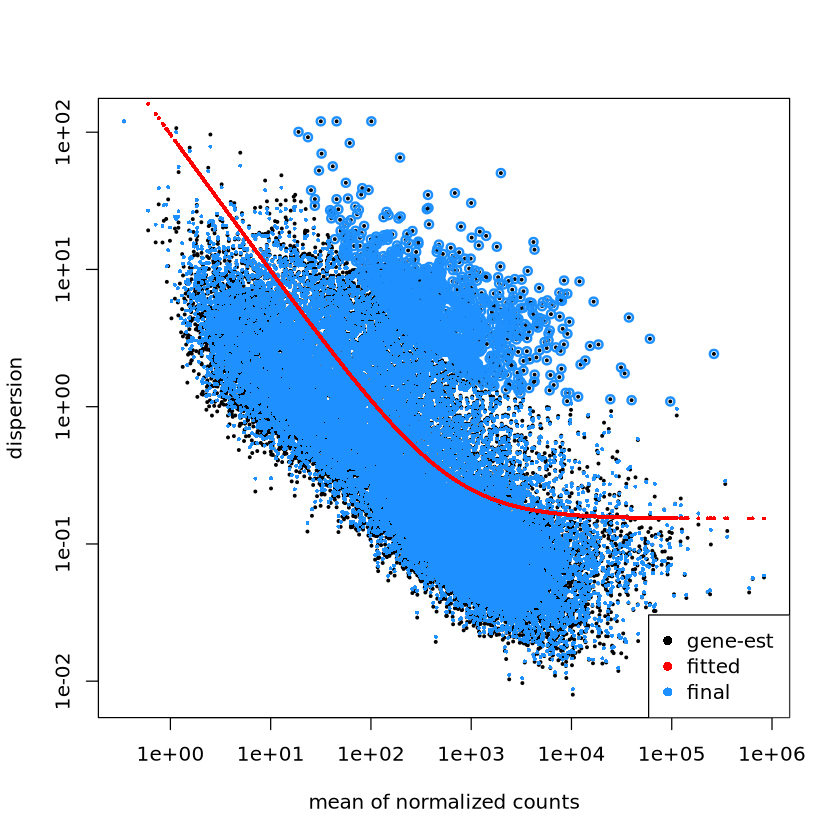

In [28]:
plotDispEsts(dds2)

### outlier detection with NMDS

In [32]:
head(sample_dists)

[1]  94.74804  97.33044 100.82440  94.83083 119.46431  99.93641

In [29]:
# normalization & transformation
vsd <- vst(dds2)

# create NMDS
sample_dists <- assay(vsd) %>% t() %>% dist()   # keep as a dist object (no as.matrix)

set.seed(123)
nmds <- metaMDS(sample_dists, k = 2, trymax = 100)
nmds_data <- data.frame(scores(nmds, display = "sites"))
nmds_df <- cbind(nmds_data, as.data.frame(colData(vsd))) %>% 
# add phase info
mutate(phase = case_when(
    is.na(Phase2_treatment) ~ '1',
    TRUE ~ '2'))
head(nmds_df)

Run 0 stress 0.006016655 
Run 1 stress 0.0001014394 
... New best solution
... Procrustes: rmse 0.009551028  max resid 0.07319267 
Run 2 stress 0.005699553 
Run 3 stress 0.003675915 
Run 4 stress 9.98573e-05 
... New best solution
... Procrustes: rmse 1.762809e-05  max resid 0.0001102095 
... Similar to previous best
Run 5 stress 0.01096874 
Run 6 stress 0.005672227 
Run 7 stress 0.006662484 
Run 8 stress 0.003223108 
Run 9 stress 0.01210281 
Run 10 stress 0.01583933 
Run 11 stress 0.0002145225 
... Procrustes: rmse 0.0003544799  max resid 0.00274132 
... Similar to previous best
Run 12 stress 0.0004175291 
... Procrustes: rmse 0.000736281  max resid 0.005665432 
... Similar to previous best
Run 13 stress 0.001294973 
Run 14 stress 0.0004102675 
... Procrustes: rmse 0.0007249636  max resid 0.005583963 
... Similar to previous best
Run 15 stress 0.006613672 
Run 16 stress 0.0002371839 
... Procrustes: rmse 0.0004084734  max resid 0.003147062 
... Similar to previous best
Run 17 stress 0

Warning message in metaMDS(sample_dists, k = 2, trymax = 100):
“stress is (nearly) zero: you may have insufficient data”


,NMDS1,NMDS2,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,sizeFactor,group,phase
,<dbl>,<dbl>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<fct>,<dbl>,<fct>,<chr>
B1_B1_O01,-3.087578,-1.616603e-03,4,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,1.0395499,both_both,2
B1_Nu_O03,-3.088211,-1.444600e-03,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1.5069493,both_NA,1
B1_W5_O50,-3.087074,-6.875286e-05,2,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,0.9935344,both_warm,2
B2_B5_O51,-3.085917,8.354130e-04,4,both,warm,hypoxic,2,both,warm,hypoxic,5,both_both,1.0431258,both_both,2
B2_C4_O40,-3.087123,-5.096957e-04,2,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,1.0980371,both_control,2
B2_Nu_O12,-3.087702,3.289918e-03,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1.2965225,both_NA,1


In [35]:
nmds_df$sample <- rownames(nmds_df)
nmds_df[which.max(nmds_df$NMDS1), c("sample", "complete_trtmt")]

# library size and mean distance to the others
d <- as.matrix(sample_dists)
sort(rowMeans(d), decreasing = TRUE)[1:5]
colSums(counts(dds2))[names(sort(rowMeans(d), decreasing = TRUE))[1:5]]

,sample,complete_trtmt
,<chr>,<fct>
B3_Nu_O24,B3_Nu_O24,both_NA


B3_Nu_O24 H2_H5_B51 B5_C1_O09 B4_H1_O07 H6_Nu_B45 
 306.1179  203.6768  200.8967  134.2550  128.8286

B3_Nu_O24 H2_H5_B51 B5_C1_O09 B4_H1_O07 H6_Nu_B45 
   664829  47701342  39479248  30744079  49550543

[1] 9.98573e-05

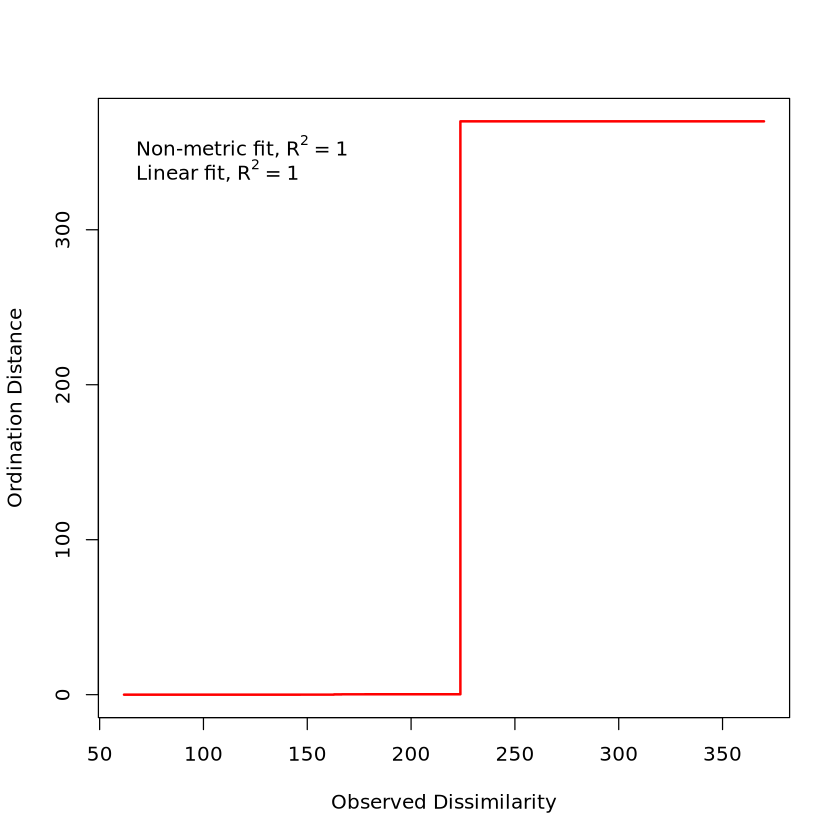

In [30]:
nmds$stress
stressplot(nmds)

something is not right ... removing outliers and trying again

In [44]:
bad <- c('B3_Nu_O24', 'B5_C1_O09', 'C1_C4_W37', 'H2_H5_B51', 'H6_Nu_B45')
dds2 <- dds2[, !(colnames(dds2) %in% bad)]
colData(dds2) <- droplevels(colData(dds2))

# re-run the gene filter, then DESeq and VST
dds2 <- estimateSizeFactors(dds2)

dds2$group <- factor(dds2$complete_trtmt)
   keep <- apply(counts(dds2, normalized = TRUE), 1, function(x) {
     any(tapply(x, dds2$group, function(g) sum(g >= 5) >= 3))
   })
dds_filtered <- dds2[keep, ]
         
dds_filtered <- DESeq(dds_filtered)
dds_filtered
vsd <- vst(dds_filtered)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



class: DESeqDataSet 
dim: 26062 115 
metadata(1): version
assays(4): counts mu H cooks
rownames(26062): LOC144621260 LOC144621269 ... LOC144621306
  LOC144621888
rowData names(94): baseMean baseVar ... deviance maxCooks
colnames(115): B1_B1_O01 B1_Nu_O03 ... W6_W3_G36 W6_W4_G48
colData names(12): Cluster Phase1_treatment ... sizeFactor group

In [45]:
# create NMDS
sample_dists <- assay(vsd) %>% t() %>% dist()   # keep as a dist object (no as.matrix)

set.seed(123)
nmds <- metaMDS(sample_dists, k = 2, trymax = 100)
nmds_data <- data.frame(scores(nmds, display = "sites"))
nmds_df <- cbind(nmds_data, as.data.frame(colData(vsd))) %>% 
# add phase info
mutate(phase = case_when(
    is.na(Phase2_treatment) ~ '1',
    TRUE ~ '2'))
head(nmds_df)

Run 0 stress 0.1909635 
Run 1 stress 0.2025418 
Run 2 stress 0.1909567 
... New best solution
... Procrustes: rmse 0.002485116  max resid 0.02410522 
Run 3 stress 0.1990773 
Run 4 stress 0.2092141 
Run 5 stress 0.2107653 
Run 6 stress 0.1964345 
Run 7 stress 0.2036195 
Run 8 stress 0.2087442 
Run 9 stress 0.1898369 
... New best solution
... Procrustes: rmse 0.02788177  max resid 0.2210789 
Run 10 stress 0.1898388 
... Procrustes: rmse 0.002166698  max resid 0.01801115 
Run 11 stress 0.1934593 
Run 12 stress 0.2126158 
Run 13 stress 0.2095998 
Run 14 stress 0.2273033 
Run 15 stress 0.1991608 
Run 16 stress 0.2340954 
Run 17 stress 0.192087 
Run 18 stress 0.2037043 
Run 19 stress 0.1956051 
Run 20 stress 0.1924842 
Run 21 stress 0.202745 
Run 22 stress 0.199047 
Run 23 stress 0.1902531 
... Procrustes: rmse 0.00879805  max resid 0.0890719 
Run 24 stress 0.1995365 
Run 25 stress 0.2274537 
Run 26 stress 0.2069966 
Run 27 stress 0.2039211 
Run 28 stress 0.1957956 
Run 29 stress 0.1971014 

,NMDS1,NMDS2,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,sizeFactor,group,phase
,<dbl>,<dbl>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<fct>,<dbl>,<fct>,<chr>
B1_B1_O01,-14.2301715,-9.375110,4,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,1.0006591,both_both,2
B1_Nu_O03,-9.6048820,-14.627860,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1.4437108,both_NA,1
B1_W5_O50,6.2028303,5.234670,2,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,0.9422678,both_warm,2
B2_B5_O51,15.6887895,23.582566,4,both,warm,hypoxic,2,both,warm,hypoxic,5,both_both,0.9965914,both_both,2
B2_C4_O40,-0.2994485,2.510347,2,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,1.0814808,both_control,2
B2_Nu_O12,51.6328708,16.052241,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1.2731193,both_NA,1


check stress:

[1] 0.1898369

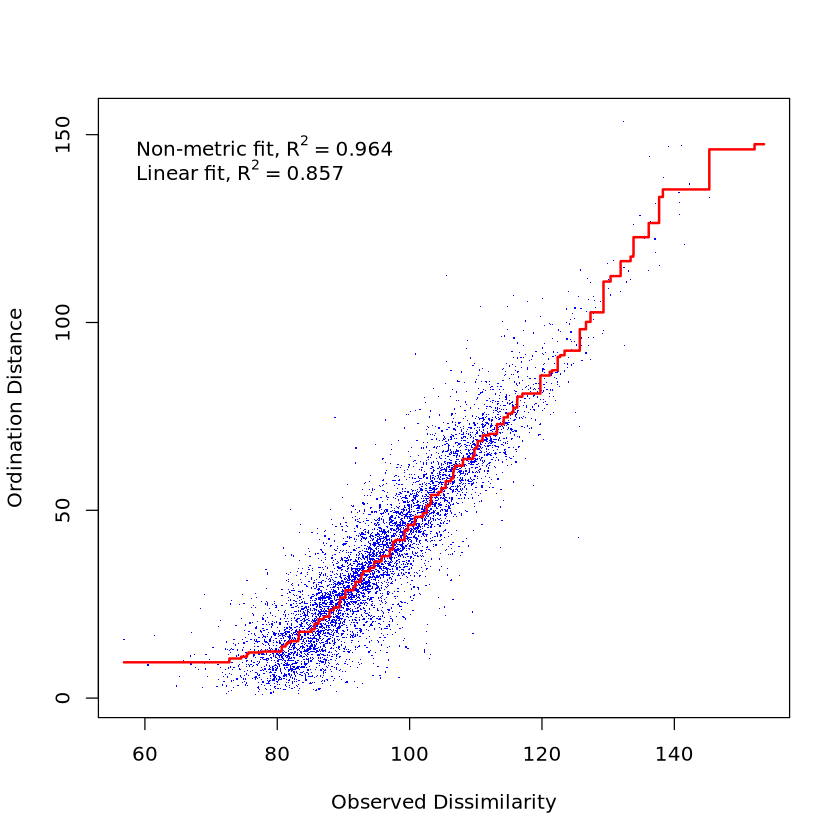

In [46]:
nmds$stress
stressplot(nmds)

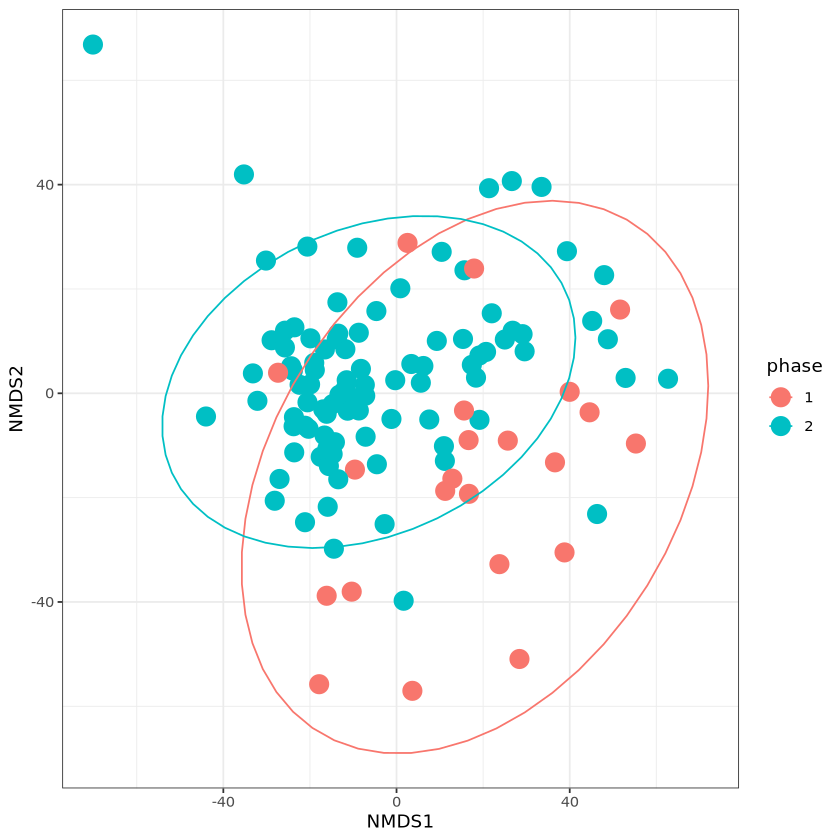

In [47]:
nmds.plot <- ggplot(nmds_df, aes(NMDS1, NMDS2, col = phase)) +
geom_point(size = 5) +
stat_ellipse() + 
theme_bw()

nmds.plot

In [48]:
# Try with large k

nmds <- metaMDS(sample_dists, k = 3, trymax = 100)
nmds_data <- data.frame(scores(nmds, display = "sites"))
nmds_df <- cbind(nmds_data, as.data.frame(colData(vsd))) %>% 
# add phase info
mutate(phase = case_when(
    is.na(Phase2_treatment) ~ '1',
    TRUE ~ '2'))
head(nmds_df)

Run 0 stress 0.1343056 
Run 1 stress 0.1346421 
... Procrustes: rmse 0.005767293  max resid 0.03930545 
Run 2 stress 0.1342906 
... New best solution
... Procrustes: rmse 0.003137104  max resid 0.02975293 
Run 3 stress 0.1343062 
... Procrustes: rmse 0.003263769  max resid 0.03095167 
Run 4 stress 0.1436911 
Run 5 stress 0.1343275 
... Procrustes: rmse 0.00389564  max resid 0.03501726 
Run 6 stress 0.1342907 
... Procrustes: rmse 0.0004606608  max resid 0.004041754 
... Similar to previous best
Run 7 stress 0.1342903 
... New best solution
... Procrustes: rmse 0.0001457955  max resid 0.0011397 
... Similar to previous best
Run 8 stress 0.1343143 
... Procrustes: rmse 0.003161317  max resid 0.02988176 
Run 9 stress 0.134297 
... Procrustes: rmse 0.001013658  max resid 0.00702558 
... Similar to previous best
Run 10 stress 0.1343057 
... Procrustes: rmse 0.003229844  max resid 0.03043253 
Run 11 stress 0.1343046 
... Procrustes: rmse 0.002962844  max resid 0.02818245 
Run 12 stress 0.134

,NMDS1,NMDS2,NMDS3,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,sizeFactor,group,phase
,<dbl>,<dbl>,<dbl>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<fct>,<dbl>,<fct>,<chr>
B1_B1_O01,-18.0296816,9.029380,10.665429,4,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,1.0006591,both_both,2
B1_Nu_O03,-12.6211789,7.097835,-22.791557,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1.4437108,both_NA,1
B1_W5_O50,7.7760952,-7.129830,-2.173296,2,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,0.9422678,both_warm,2
B2_B5_O51,18.8163544,-6.252167,28.261023,4,both,warm,hypoxic,2,both,warm,hypoxic,5,both_both,0.9965914,both_both,2
B2_C4_O40,-0.2649796,-5.412857,-7.282215,2,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,1.0814808,both_control,2
B2_Nu_O12,53.3265509,-15.172171,-18.842688,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1.2731193,both_NA,1


[1] 0.1342903

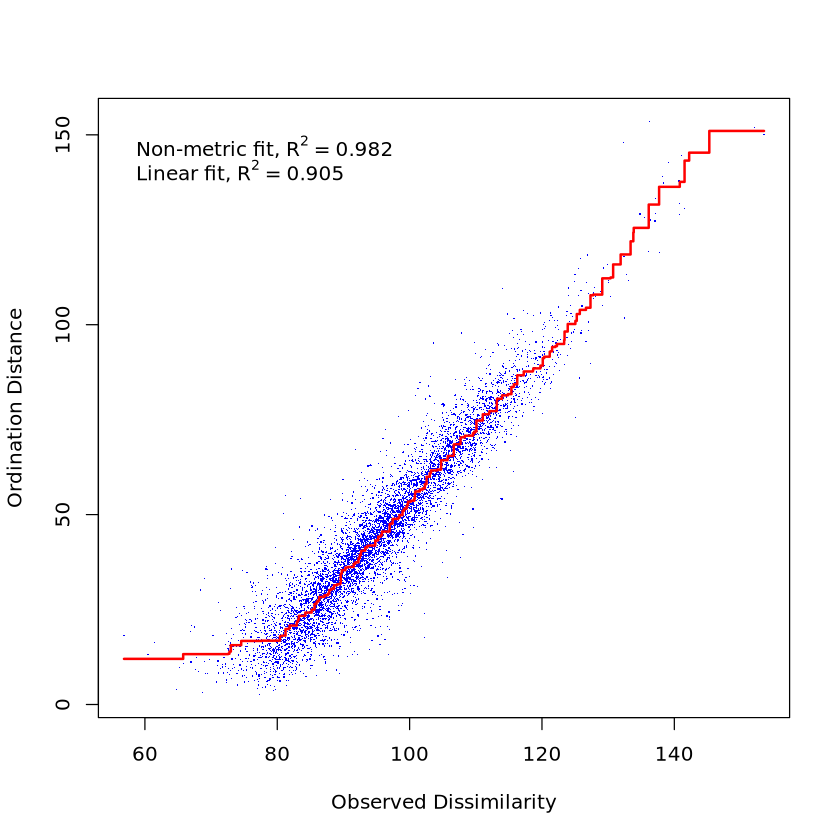

In [49]:
nmds$stress
stressplot(nmds)

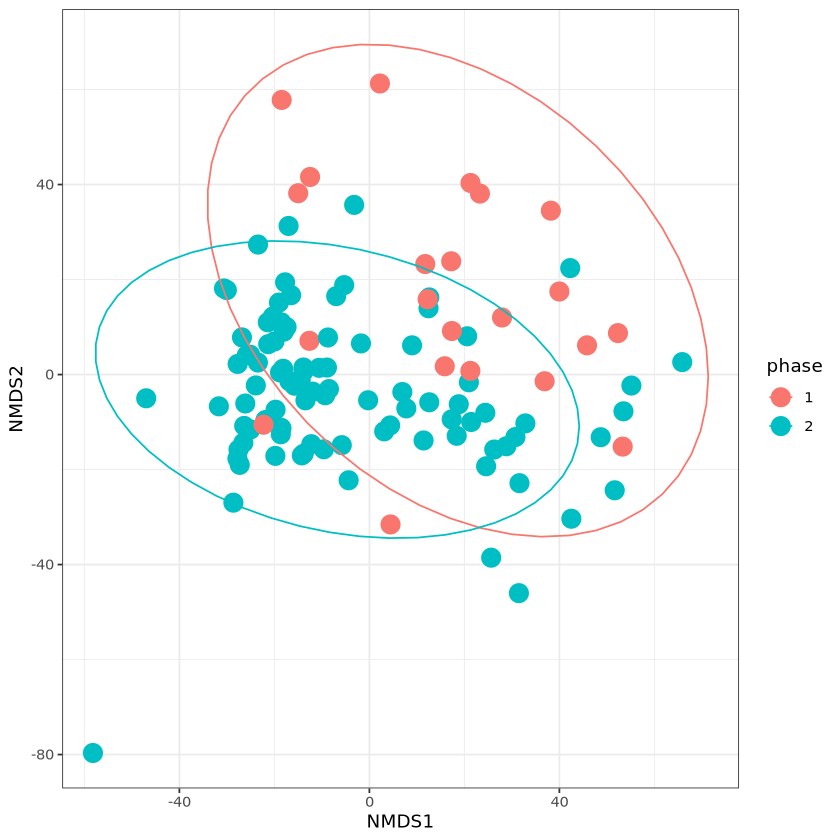

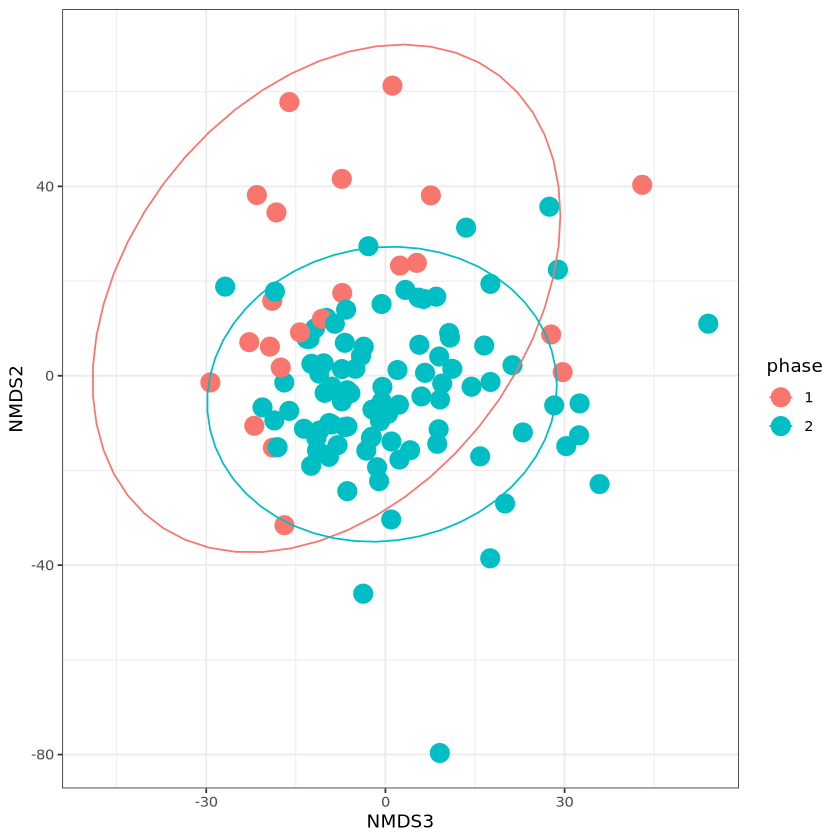

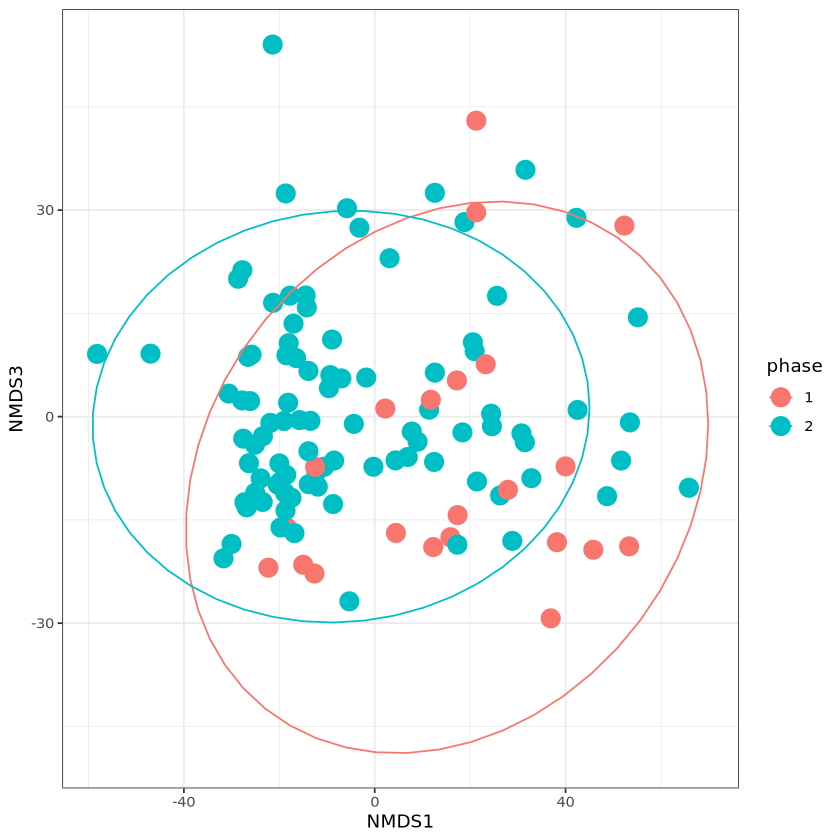

In [50]:
ggplot(nmds_df, aes(NMDS1, NMDS2, col = phase)) +
geom_point(size = 5) +
stat_ellipse() + 
theme_bw()

ggplot(nmds_df, aes(NMDS3, NMDS2, col = phase)) +
geom_point(size = 5) +
stat_ellipse() + 
theme_bw()

ggplot(nmds_df, aes(NMDS1, NMDS3, col = phase)) +
geom_point(size = 5) +
stat_ellipse() + 
theme_bw()

### heatmap sample-to-sample distance

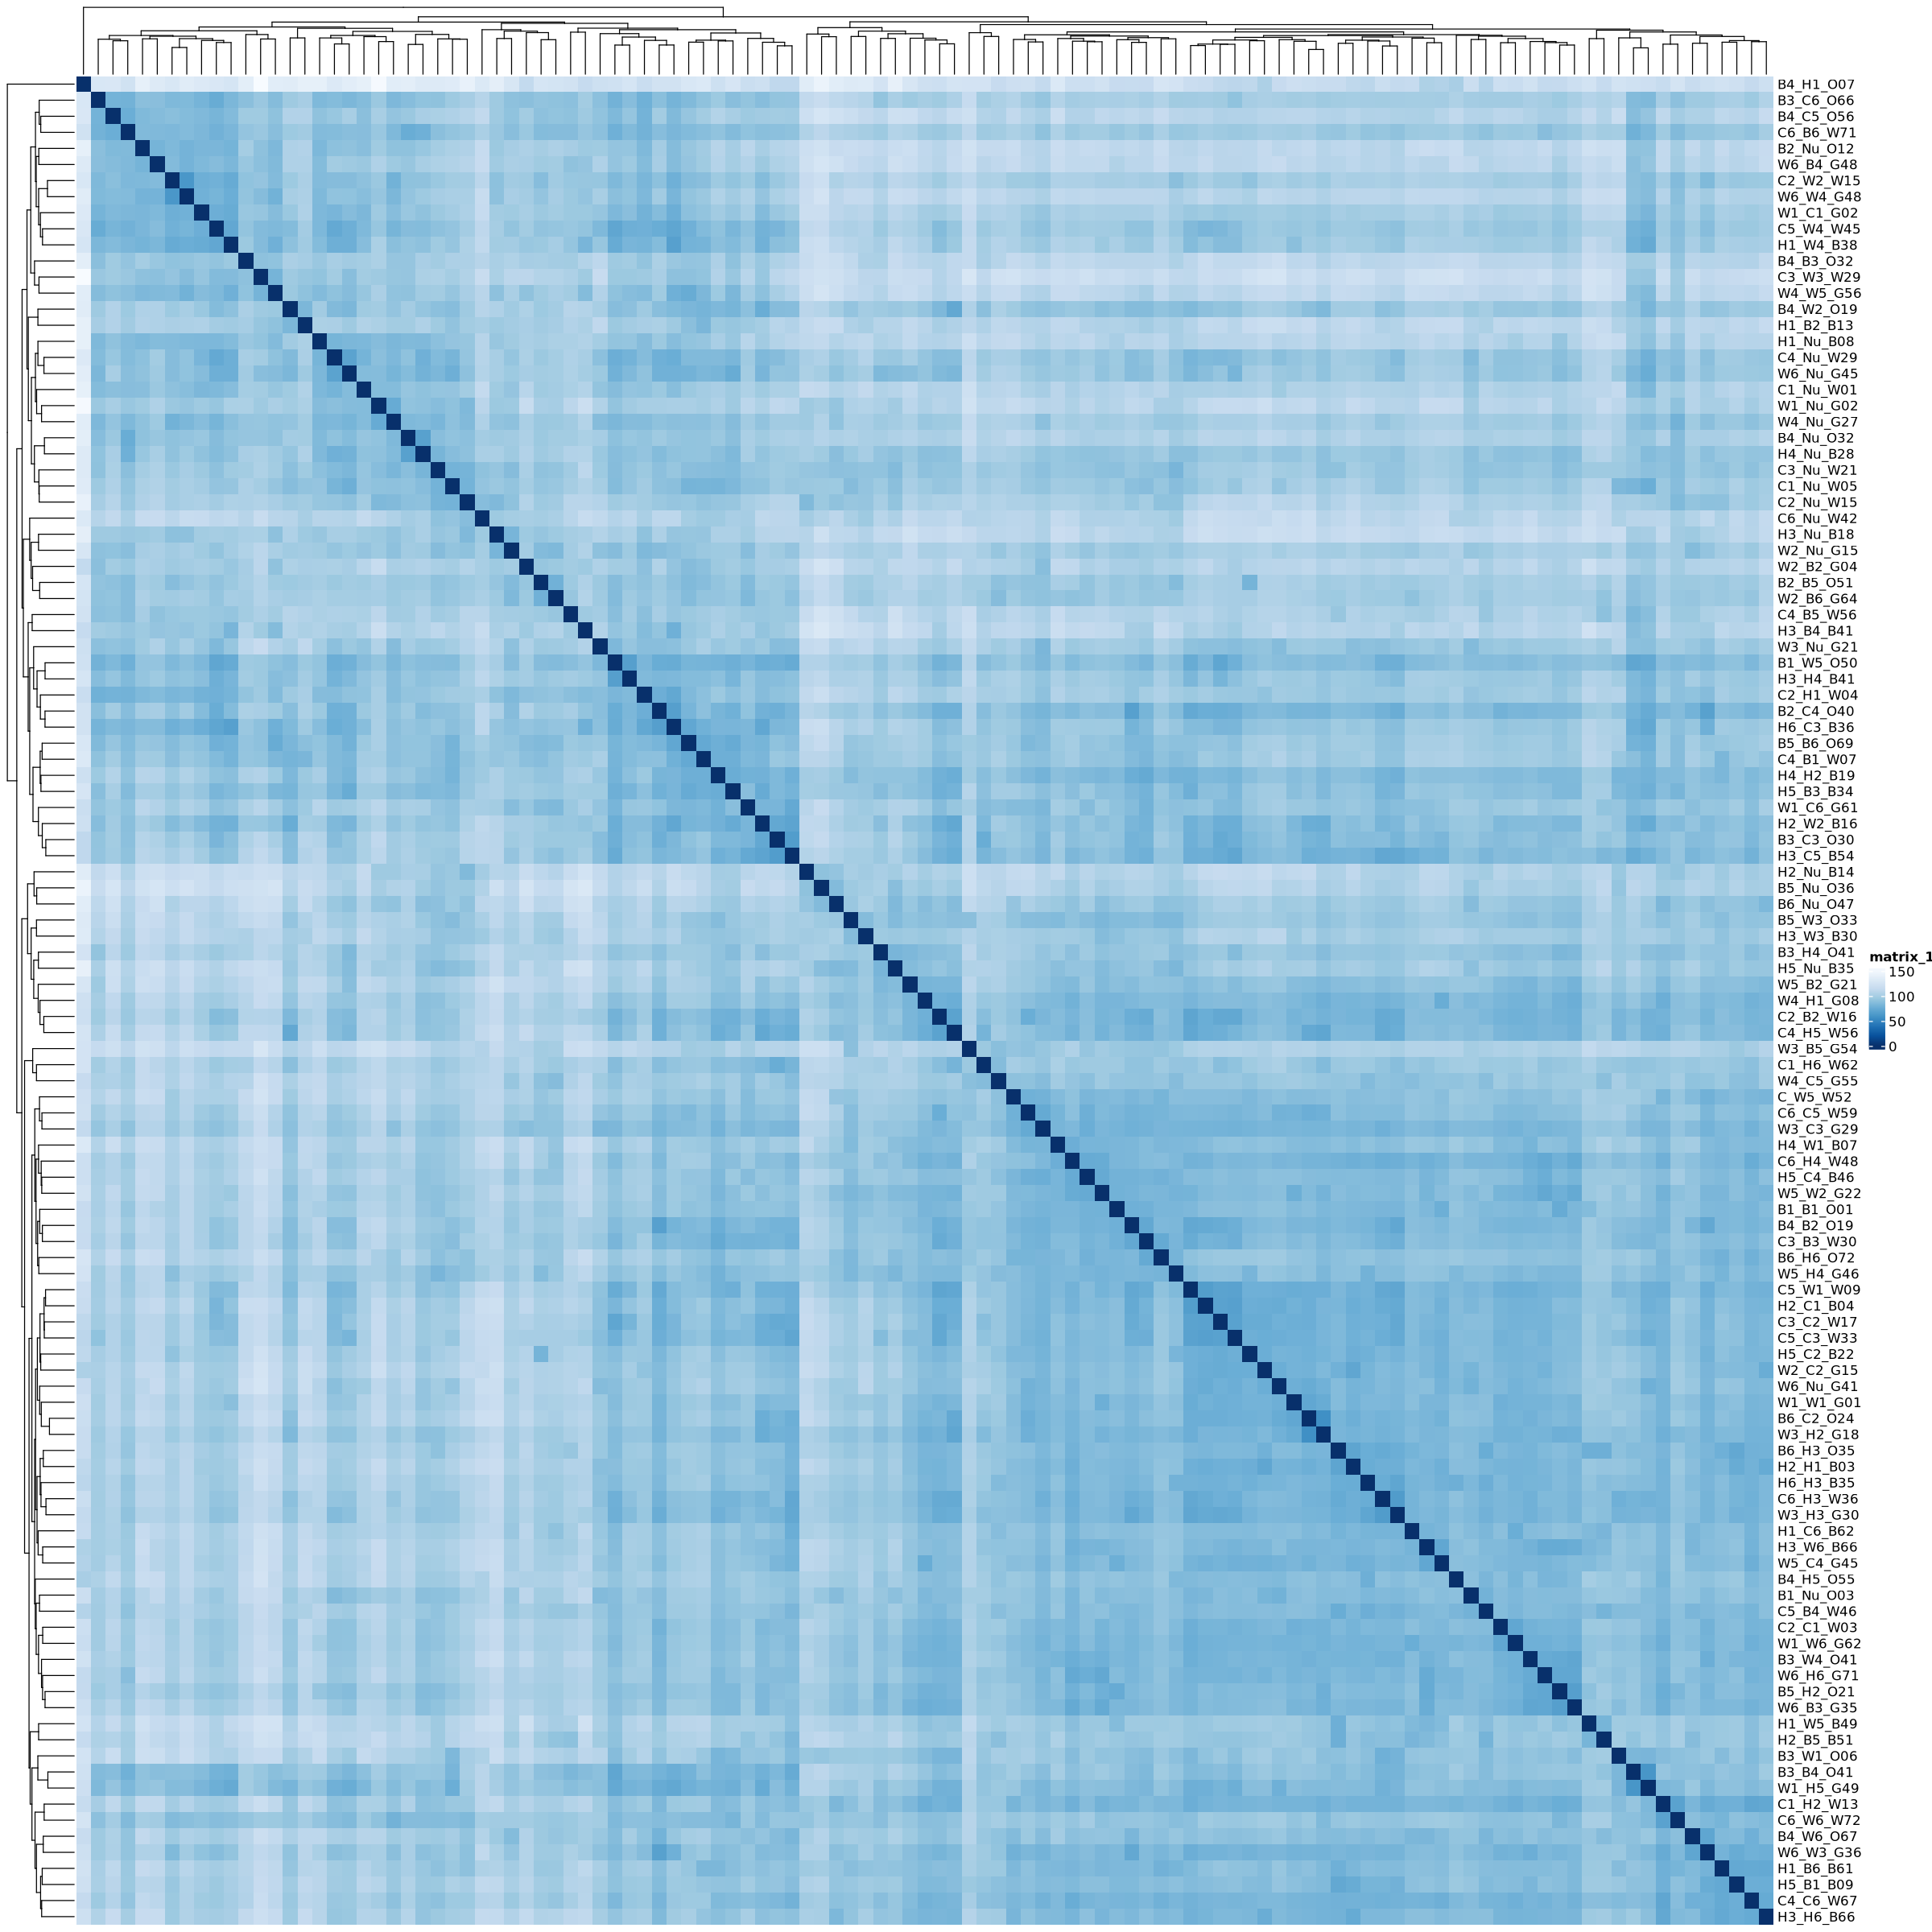

In [51]:
options(repr.plot.width=20, repr.plot.height=20)

sampleDistMatrix <- as.matrix(sample_dists)
rownames(sampleDistMatrix) <- paste(colnames(vsd))
colnames(sampleDistMatrix) <- NULL
colors <- colorRampPalette( rev(brewer.pal(9, "Blues")) )(255)
pheatmap(sampleDistMatrix,
         clustering_distance_rows = sample_dists,
         clustering_distance_cols = sample_dists,
         col = colors)

In [58]:
write.csv(assay(vsd), '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/vst_allSamples.csv')

#### relatedness nmds

In [60]:
nmds_df$Cluster <- as.character(nmds_df$Cluster)

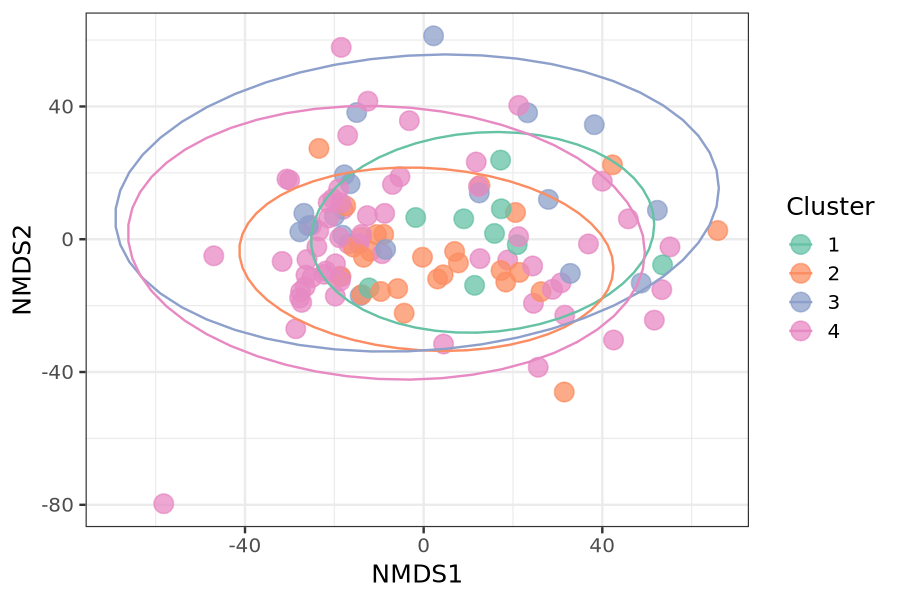

In [61]:
options(repr.plot.height = 5, repr.plot.width = 7.5)

nmds.plot <- ggplot(nmds_df, aes(NMDS1, NMDS2, col = Cluster)) +
geom_point(size = 5, alpha = 0.75) +
stat_ellipse() + 
scale_color_brewer(palette = 'Set2') +
theme_bw(base_size = 15)

nmds.plot

according to [the relatedness heatmap](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/variant_calling/relatedness.ipynb) - cluster 1 and 2 are part of the same group (but got separated for some reason in the heatmap), cluster 3 is another familiar cluster, and cluster 4 is more of a catch all

let's combine 1 and 2? 

In [63]:
cluster.df <- nmds_df %>% mutate(cluster2 = case_when(
    Cluster %in% c(1,2) ~ 'A',
    Cluster == 3 ~ 'B',
    Cluster == 4 ~ 'C'))

head(cluster.df)

,NMDS1,NMDS2,NMDS3,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,sizeFactor,group,phase,cluster2
,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<fct>,<dbl>,<fct>,<chr>,<chr>
B1_B1_O01,-18.0296816,9.029380,10.665429,4,both,warm,hypoxic,1,both,warm,hypoxic,1,both_both,1.0006591,both_both,2,C
B1_Nu_O03,-12.6211789,7.097835,-22.791557,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1.4437108,both_NA,1,C
B1_W5_O50,7.7760952,-7.129830,-2.173296,2,both,warm,hypoxic,1,warm,warm,normoxic,5,both_warm,0.9422678,both_warm,2,A
B2_B5_O51,18.8163544,-6.252167,28.261023,4,both,warm,hypoxic,2,both,warm,hypoxic,5,both_both,0.9965914,both_both,2,C
B2_C4_O40,-0.2649796,-5.412857,-7.282215,2,both,warm,hypoxic,2,control,ambient,normoxic,4,both_control,1.0814808,both_control,2,A
B2_Nu_O12,53.3265509,-15.172171,-18.842688,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1.2731193,both_NA,1,C


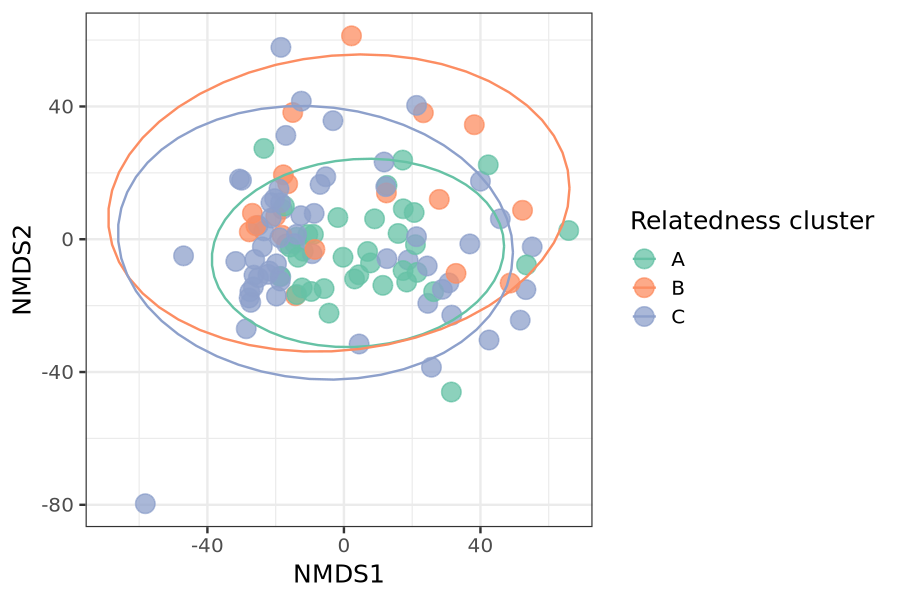

In [64]:
nmds.plot <- ggplot(cluster.df, aes(NMDS1, NMDS2, col = cluster2)) +
geom_point(size = 5, alpha = 0.75) +
stat_ellipse() + 
scale_color_brewer(palette = 'Set2') +
theme_bw(base_size = 15) +
labs(col = 'Relatedness cluster')

nmds.plot

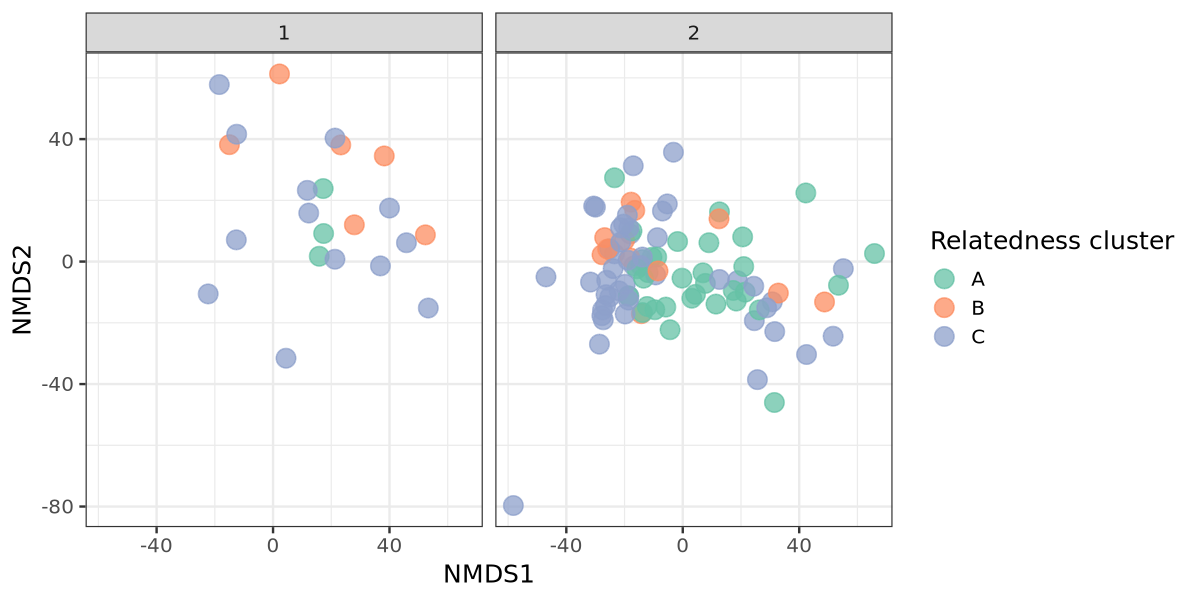

In [65]:
options(repr.plot.height = 5, repr.plot.width = 10)

nmds.plot <- ggplot(cluster.df, aes(NMDS1, NMDS2, col = cluster2)) +
geom_point(size = 5, alpha = 0.75) +
#stat_ellipse() + 
facet_wrap(~phase) +
scale_color_brewer(palette = 'Set2') +
theme_bw(base_size = 15) +
labs(col = 'Relatedness cluster')

nmds.plot

even mix of related invidiuals in phase 1 and 2 oysters? so maybe not a concern in analysis?

In [66]:
set.seed(123)

adonis2(sample_dists ~ phase * cluster2,
        data = cluster.df, 
        permutations = 999)

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
phase,1,24553.928,0.0464031,5.7749860,0.001
cluster2,2,33748.287,0.0637790,3.9687312,0.001
phase:cluster2,2,7398.706,0.0139824,0.8700731,0.788
Residual,109,463443.239,0.8758355,NA,NA
Total,114,529144.161,1.0000000,NA,NA


(idk if I did this right bc I'm doing it quick...) there's a significant effect of relationship cluster on transcriptional profile 

#### age nmds

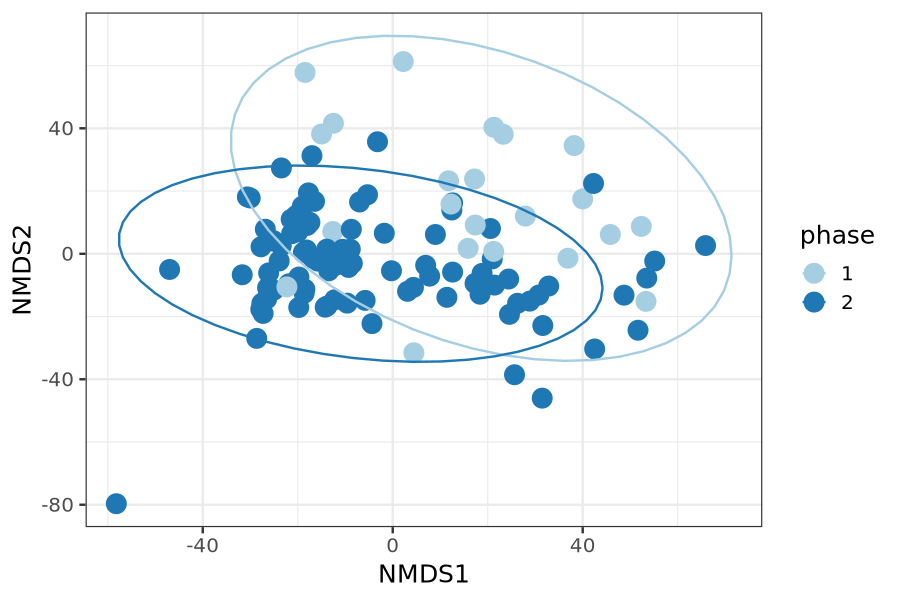

In [68]:
options(repr.plot.height = 5, repr.plot.width = 7.5)

nmds.plot <- ggplot(nmds_df, aes(NMDS1, NMDS2, col = phase)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_color_brewer(palette = 'Paired') +
theme_bw(base_size = 15)

nmds.plot

seems like age of the sample has a big effect on transcriptional profiles - there's a pretty nice clustering of phase 1 and phase 2 oysters

to make phase 1 and 2 more comparable, want to subset the phase 2 oysters for those that experienced control conditions in phase 1 (so we're comparing even numbers and only focusing on the most recent exposure)

In [69]:
nmds.subset <- nmds_df %>% filter(Phase1_treatment == 'control' | is.na(Phase2_treatment))
dim(nmds.subset)
head(nmds.subset)

[1] 45 16

,NMDS1,NMDS2,NMDS3,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,sizeFactor,group,phase
,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<fct>,<dbl>,<fct>,<chr>
B1_Nu_O03,-12.62118,7.097835,-22.791557,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1.4437108,both_NA,1
B2_Nu_O12,53.32655,-15.172171,-18.842688,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1.2731193,both_NA,1
B4_Nu_O32,39.99825,17.479066,-7.230933,4,both,warm,hypoxic,4,NA,NA,NA,NA,both_NA,1.4444470,both_NA,1
B5_Nu_O36,-18.46355,57.804689,-16.086413,4,both,warm,hypoxic,5,NA,NA,NA,NA,both_NA,1.0760263,both_NA,1
B6_Nu_O47,-14.98556,38.173899,-21.520061,3,both,warm,hypoxic,6,NA,NA,NA,NA,both_NA,1.1608928,both_NA,1
C_W5_W52,-27.73459,2.229089,21.270343,3,control,ambient,normoxic,NA,warm,warm,normoxic,5,control_warm,0.9974185,control_warm,2


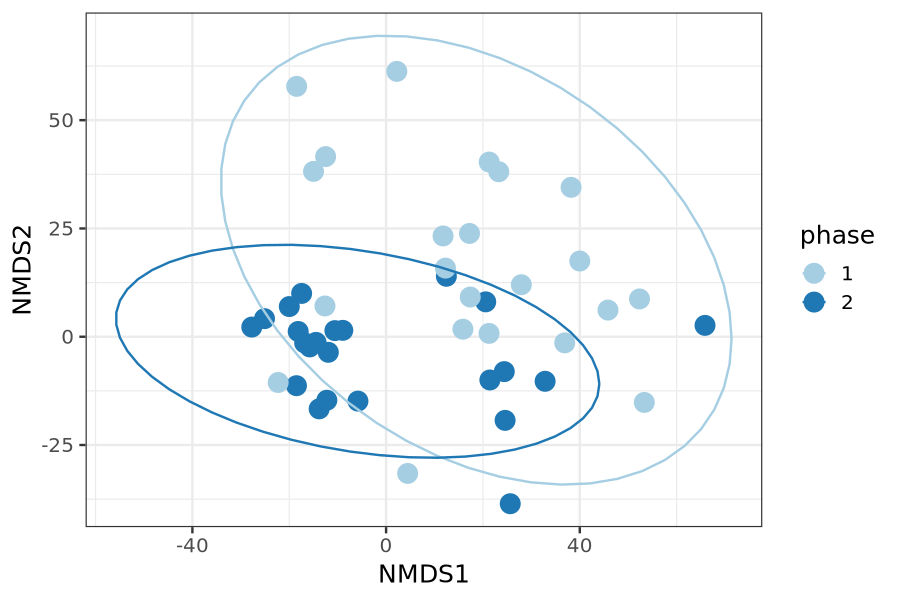

In [70]:
nmds.plot <- ggplot(nmds.subset, aes(NMDS1, NMDS2, col = phase)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_color_brewer(palette = 'Paired') +
theme_bw(base_size = 15) 

nmds.plot

seems like the phases only separate on NMDS1 and not so much on NMDS2

#### PERMANOVA

In [80]:
sample_dists <- assay(vsd) %>%
t() %>%
dist() %>%
as.matrix()

In [81]:
sample_dists.subset <- sample_dists[rownames(sample_dists) %in% rownames(nmds.stress), colnames(sample_dists) %in% rownames(nmds.stress)]
dim(sample_dists.subset)

[1] 45 45

In [82]:
set.seed(123)

adonis2(sample_dists.subset ~ phase * recent_temp * recent_DO,
        data = nmds.stress, 
        permutations = 999)

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
phase,1,16396.755,0.07944657,3.7745848,0.001
recent_temp,1,5047.636,0.02445712,1.1619817,0.217
recent_DO,1,5081.914,0.02462321,1.1698728,0.187
phase:recent_temp,1,7377.674,0.03574676,1.6983638,0.018
phase:recent_DO,1,3856.047,0.01868356,0.8876742,0.612
recent_temp:recent_DO,1,3883.336,0.01881578,0.8939563,0.615
phase:recent_temp:recent_DO,1,4016.239,0.01945973,0.9245509,0.530
Residual,37,160727.595,0.77876728,NA,NA
Total,44,206387.197,1.00000000,NA,NA


there's no interaction of recent temp and DO, so I can safely lump both and warm together

In [71]:
nmds.stress <- nmds.subset %>%
# TREATMENT
mutate(recent_stress = case_when(
    is.na(Phase2_treatment) ~ Phase1_treatment,
    TRUE ~ Phase2_treatment)) %>%
# TEMPERATURE
mutate(recent_temp = case_when(
    is.na(Phase2_treatment) ~ Phase1_temp,
    TRUE ~ Phase2_temp)) %>%
# DISSOLVED OXYGEN
mutate(recent_DO = case_when(
    is.na(Phase2_treatment) ~ Phase1_DO,
    TRUE ~ Phase2_DO))

head(nmds.stress)

,NMDS1,NMDS2,NMDS3,Cluster,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,sizeFactor,group,phase,recent_stress,recent_temp,recent_DO
,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<fct>,<dbl>,<fct>,<chr>,<chr>,<chr>,<chr>
B1_Nu_O03,-12.62118,7.097835,-22.791557,4,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1.4437108,both_NA,1,both,warm,hypoxic
B2_Nu_O12,53.32655,-15.172171,-18.842688,4,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1.2731193,both_NA,1,both,warm,hypoxic
B4_Nu_O32,39.99825,17.479066,-7.230933,4,both,warm,hypoxic,4,NA,NA,NA,NA,both_NA,1.4444470,both_NA,1,both,warm,hypoxic
B5_Nu_O36,-18.46355,57.804689,-16.086413,4,both,warm,hypoxic,5,NA,NA,NA,NA,both_NA,1.0760263,both_NA,1,both,warm,hypoxic
B6_Nu_O47,-14.98556,38.173899,-21.520061,3,both,warm,hypoxic,6,NA,NA,NA,NA,both_NA,1.1608928,both_NA,1,both,warm,hypoxic
C_W5_W52,-27.73459,2.229089,21.270343,3,control,ambient,normoxic,NA,warm,warm,normoxic,5,control_warm,0.9974185,control_warm,2,warm,warm,normoxic


In [91]:
nmds.stress <- nmds.stress %>% mutate(age = case_when(
    phase == '1' ~ 'Younger',
    phase == '2' ~ 'Older'))

nmds.stress$age <- factor(nmds.stress$age, levels = c('Younger', 'Older'))

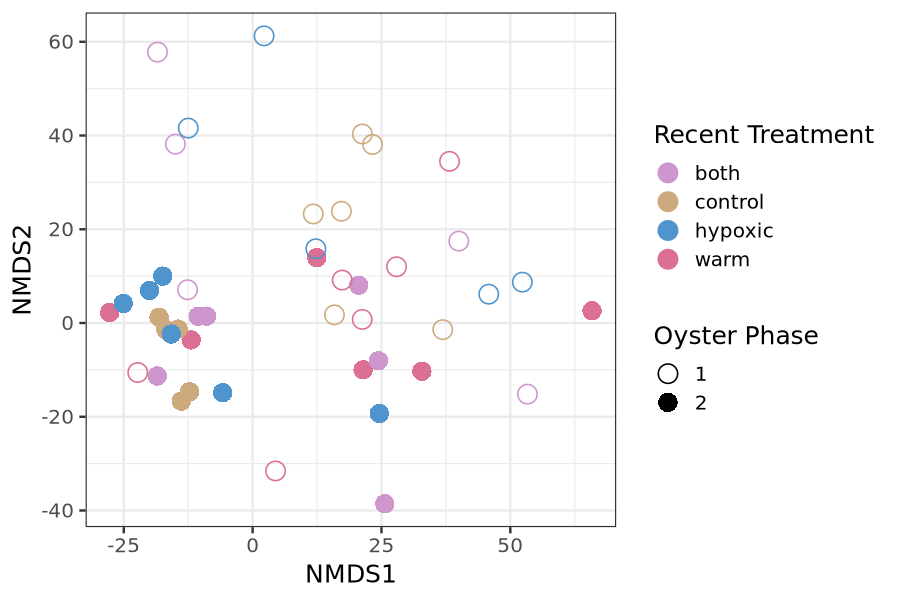

In [98]:
ggplot(nmds.stress, aes(NMDS1, NMDS2, col = recent_stress, shape = phase)) +
geom_point(size = 5) +
scale_shape_manual(values = c(1, 16)) +
#stat_ellipse() + 
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
theme_bw(base_size = 15) +
labs(col = 'Recent Treatment',
     shape = 'Oyster Phase')

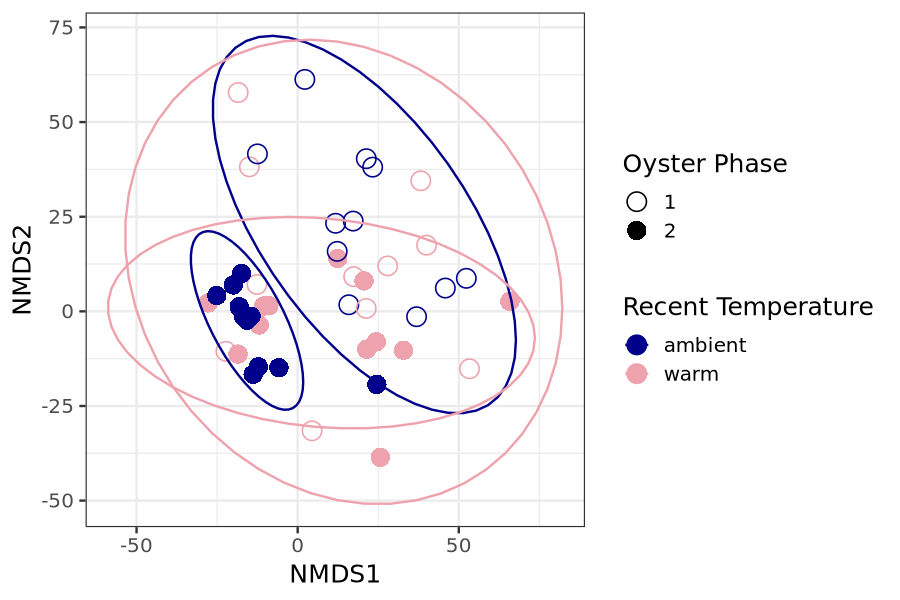

Warning message in MASS::cov.trob(data[, vars], wt = weight * nrow(data)):
“Probable convergence failure”


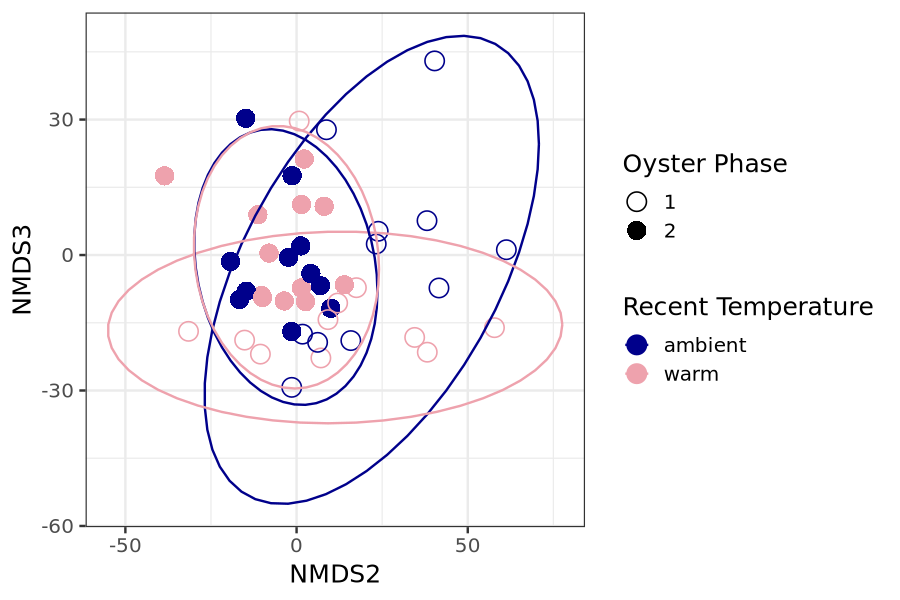

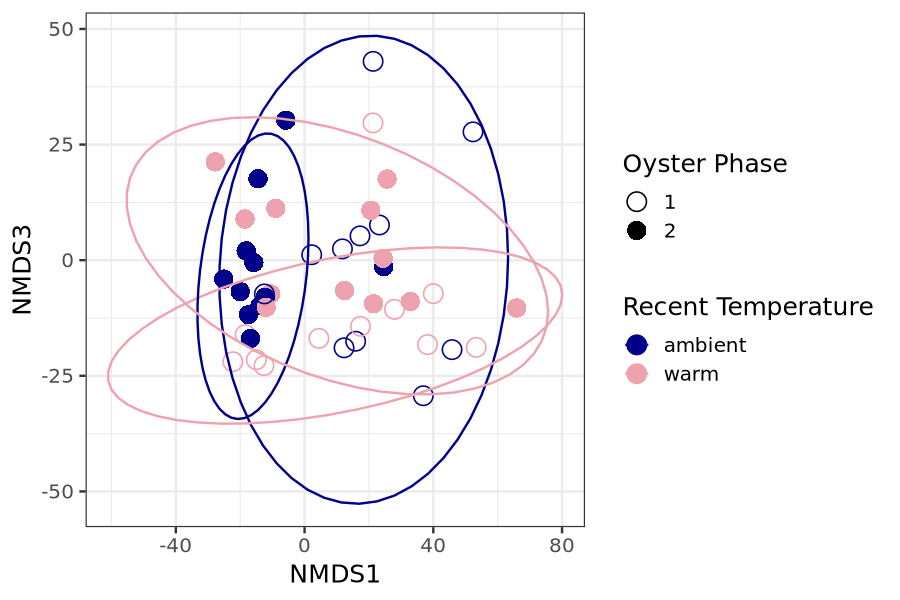

In [119]:
ggplot(nmds.stress, aes(NMDS1, NMDS2, shape = phase, col = recent_temp)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('blue4', 'lightpink2')) +
theme_bw(base_size = 15) +
labs(col = 'Recent Temperature',
     shape = 'Oyster Phase')

ggplot(nmds.stress, aes(NMDS2, NMDS3, shape = phase, col = recent_temp)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('blue4', 'lightpink2')) +
theme_bw(base_size = 15) +
labs(col = 'Recent Temperature',
     shape = 'Oyster Phase')

ggplot(nmds.stress, aes(NMDS1, NMDS3, shape = phase, col = recent_temp)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('blue4', 'lightpink2')) +
theme_bw(base_size = 15) +
labs(col = 'Recent Temperature',
     shape = 'Oyster Phase')

hmmm okay! the ambient temperatures are very distinct transcriptionally, while the warm temperatures have more overlap - so the transcriptional response to temperature is more similar, regardless of age

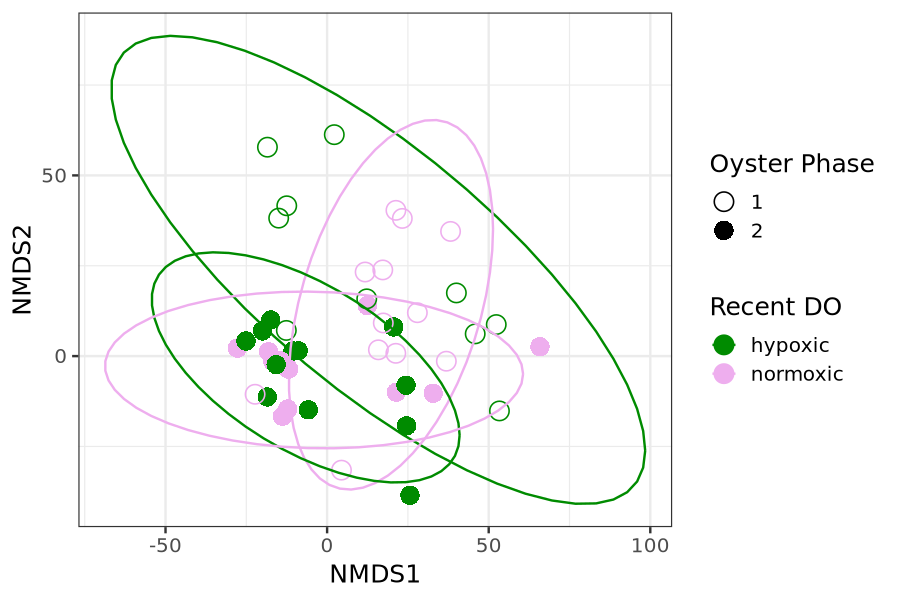

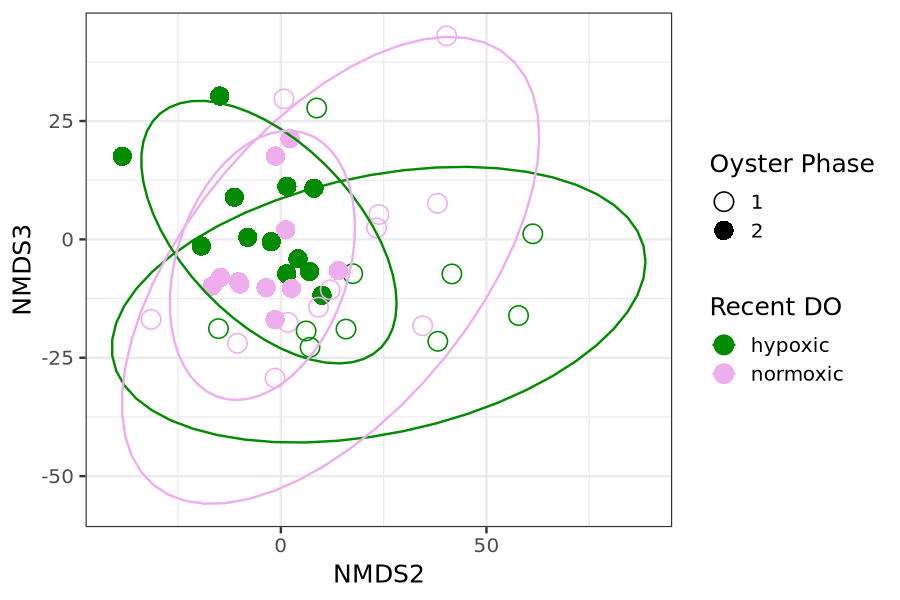

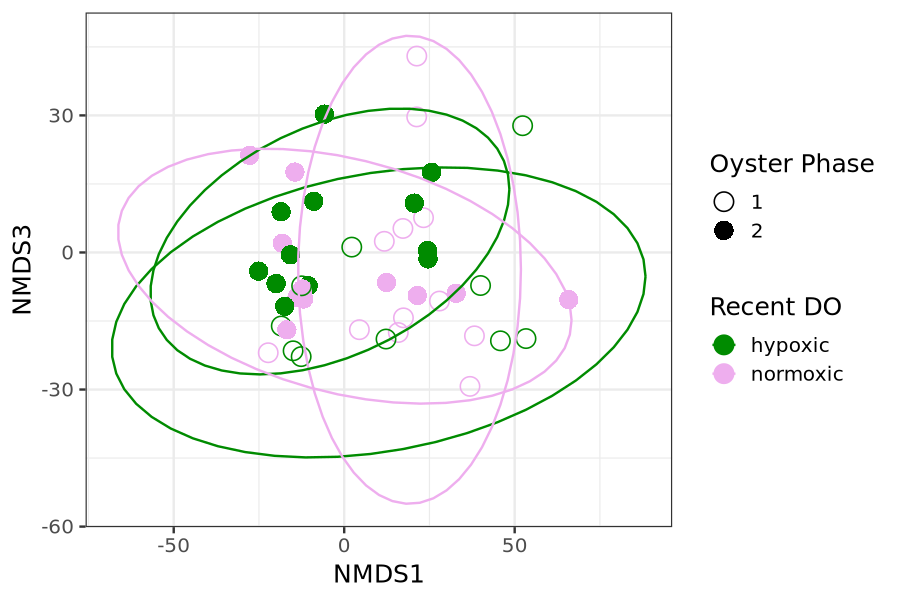

In [120]:
ggplot(nmds.stress, aes(NMDS1, NMDS2, shape = phase, col = recent_DO)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('green4', 'plum2')) +
theme_bw(base_size = 15) +
labs(col = 'Recent DO',
     shape = 'Oyster Phase')

ggplot(nmds.stress, aes(NMDS2, NMDS3, shape = phase, col = recent_DO)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('green4', 'plum2')) +
theme_bw(base_size = 15) +
labs(col = 'Recent DO',
     shape = 'Oyster Phase')

ggplot(nmds.stress, aes(NMDS1, NMDS3, shape = phase, col = recent_DO)) +
geom_point(size = 5) +
stat_ellipse() + 
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('green4', 'plum2')) +
theme_bw(base_size = 15) +
labs(col = 'Recent DO',
     shape = 'Oyster Phase')

here, hypoxic is more distinct/less overlapping, but normoxic oysters still don't have a ton of overlap (even after adding more components, we still don't see separation for DO)

Oh! but for WGCNA, I should also run it on the subset with a column for most recent exposure to see if any modules remain correlated with a stressor regardless of the age of the oyster!

### PCA
FC suggested visualizing with PCA as well, which is similar to an NMDS but will report how much of the variance is explained by a component

In [168]:
# subset vsd to only include phase 1 and phase 2 with control for phase 1
vsd.subset <- vsd[, colnames(vsd) %in% rownames(nmds.stress)]

In [131]:
meta <- meta %>%
  mutate(
    phase         = case_when(is.na(Phase2_treatment) ~ "1", TRUE ~ "2"),
    recent_stress = case_when(phase == "1" ~ Phase1_treatment, phase == "2" ~ Phase2_treatment),
    recent_temp   = case_when(phase == "1" ~ Phase1_temp,      phase == "2" ~ Phase2_temp),
    recent_DO     = case_when(phase == "1" ~ Phase1_DO,        phase == "2" ~ Phase2_DO)
  )

In [219]:
# match order to the samples in vsd
meta2 <- meta[colnames(vsd.subset), ]

# or add several at once
colData(vsd.subset) <- cbind(colData(vsd.subset), meta2[, c("phase", "recent_stress", "recent_temp", "recent_DO")])

In [170]:
pcaData <- plotPCA(vsd.subset, intgroup = c("phase", "recent_stress", "recent_temp", "recent_DO"), returnData = TRUE)
percentVar <- round(100 * attr(pcaData, "percentVar"))

using ntop=500 top features by variance



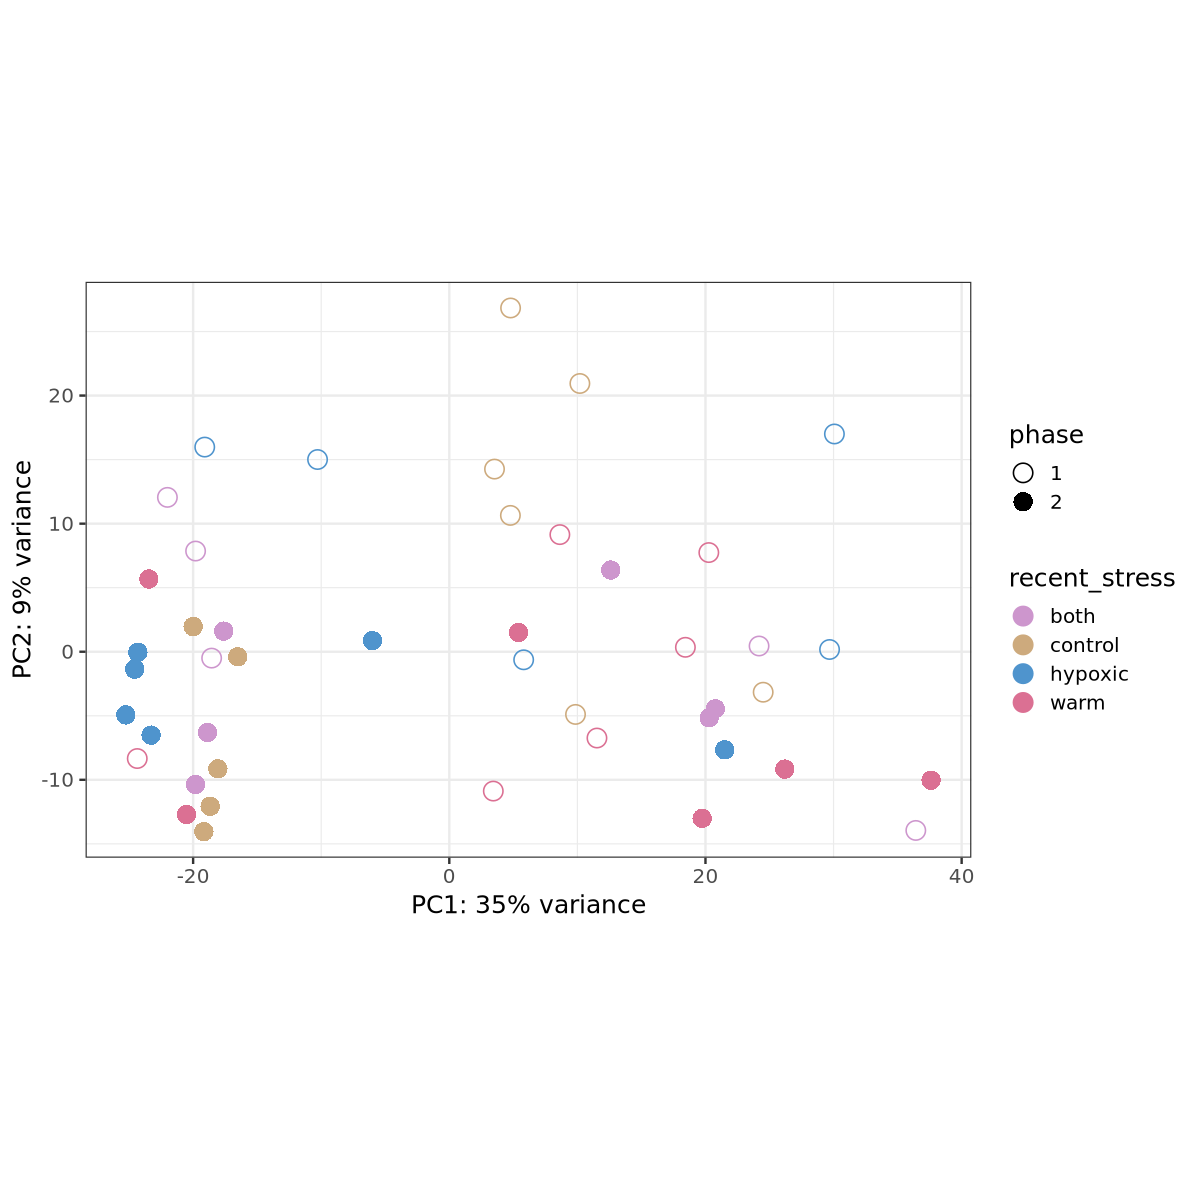

In [174]:
options(repr.plot.height = 10, repr.plot.width = 10)

ggplot(pcaData, aes(PC1, PC2, color = recent_stress, shape = phase)) +
  geom_point(size = 5) + 
scale_shape_manual(values = c(1, 16)) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
  coord_fixed() +
  theme_bw(base_size = 15)

seems like most of the filled in circles (phase 2 oysters) are on the left side of the plot?

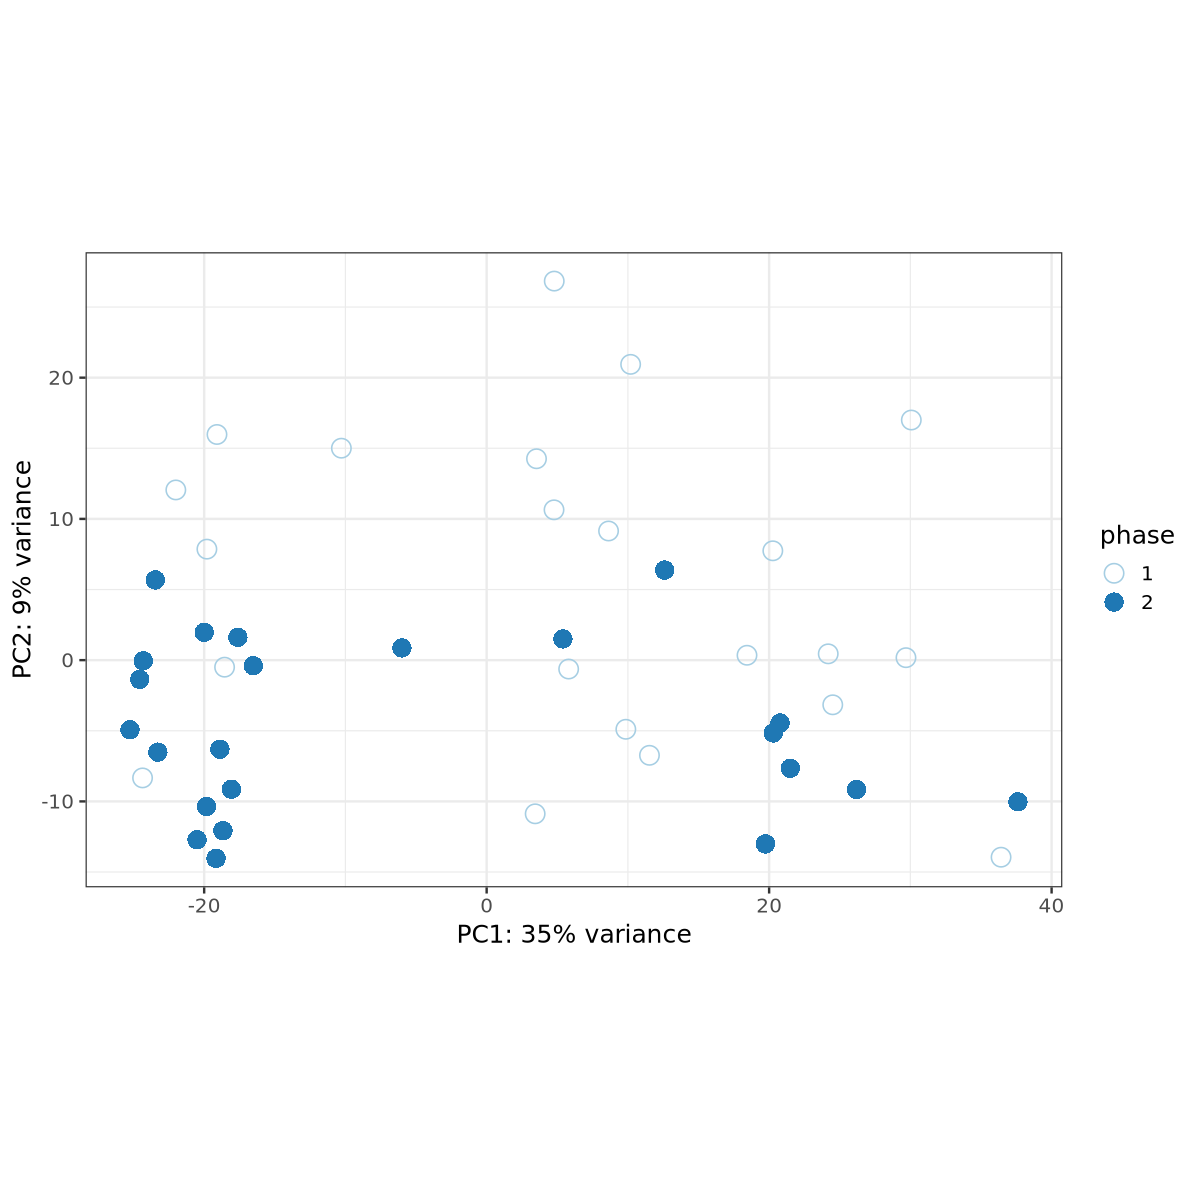

In [181]:
options(repr.plot.height = 10, repr.plot.width = 10)

ggplot(pcaData, aes(PC1, PC2, color = phase, shape = phase)) +
  geom_point(size = 5) + 
scale_shape_manual(values = c(1, 16)) +
scale_color_brewer(palette = 'Paired') +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
#scale_color_manual(values = c("hypoxic" = "steelblue3", "warm" = "palevioletred", "control" = "burlywood3", "both" = "plum3")) +
  coord_fixed() +
  theme_bw(base_size = 15)

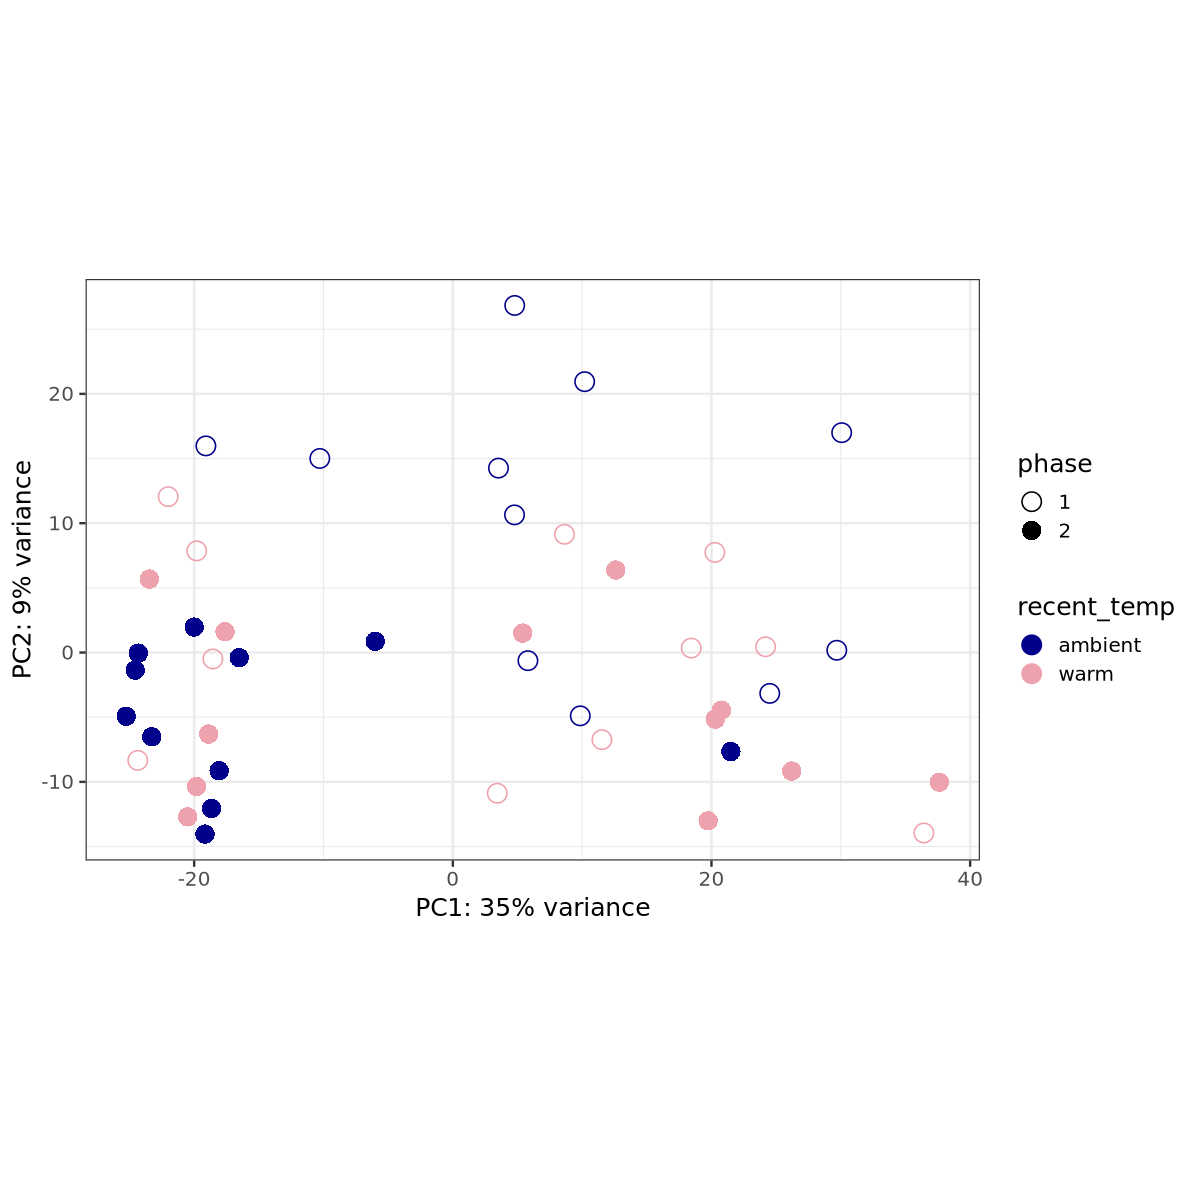

In [175]:
options(repr.plot.height = 10, repr.plot.width = 10)

ggplot(pcaData, aes(PC1, PC2, color = recent_temp, shape = phase)) +
  geom_point(size = 5) +
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('blue4', 'lightpink2')) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  coord_fixed() +
  theme_bw(base_size = 15)

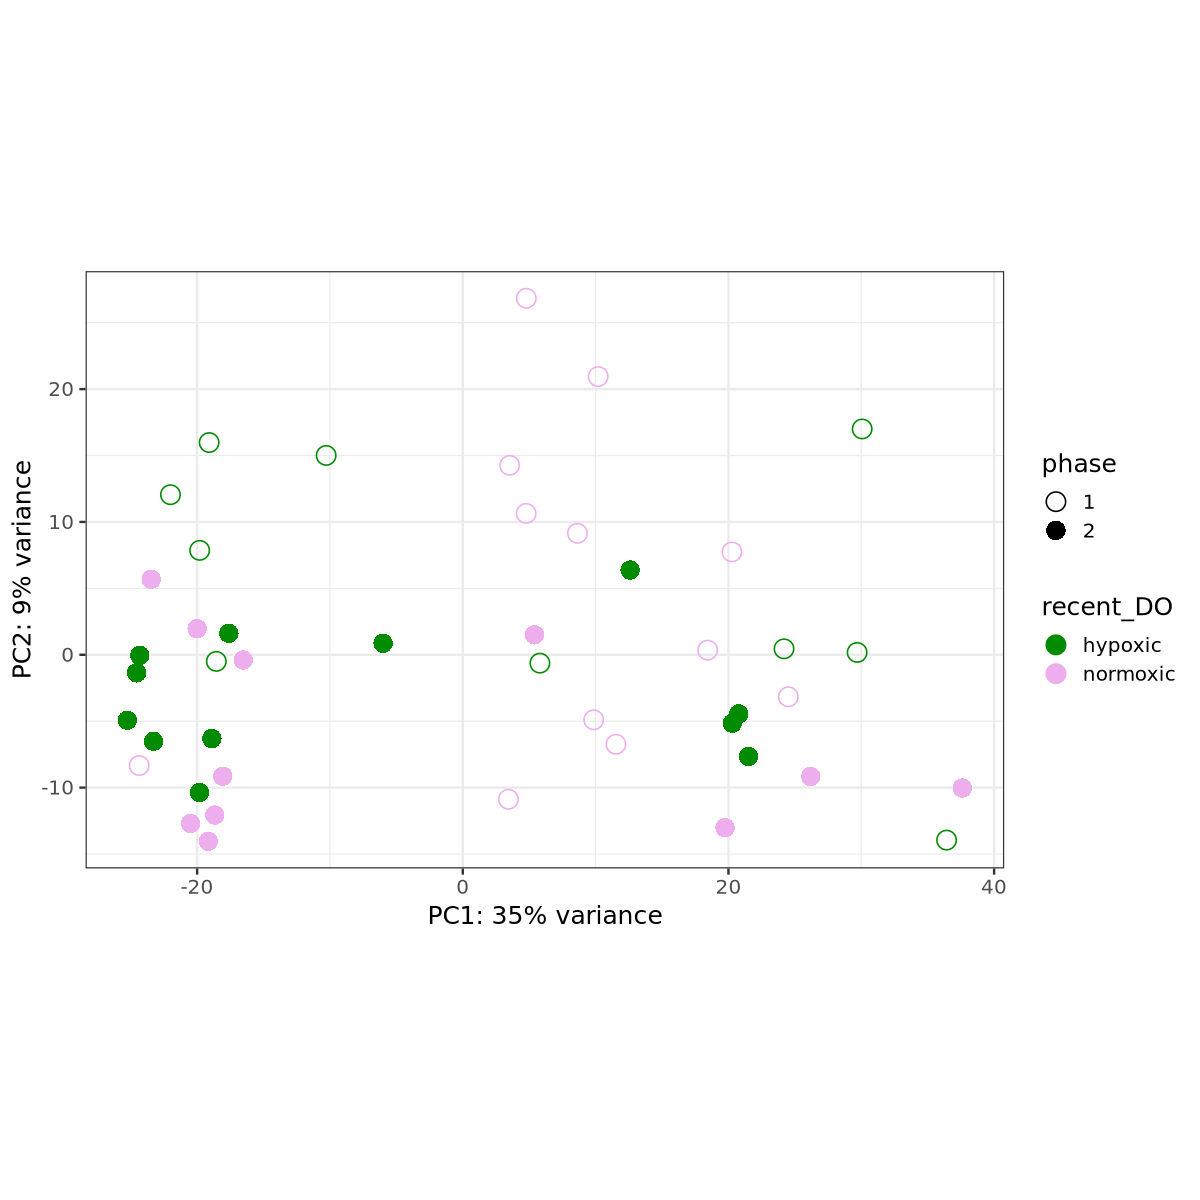

In [176]:
options(repr.plot.height = 10, repr.plot.width = 10)

ggplot(pcaData, aes(PC1, PC2, color = recent_DO, shape = phase)) +
  geom_point(size = 5) +
scale_shape_manual(values = c(1, 16)) +
scale_color_manual(values = c('green4', 'plum2')) +
  xlab(paste0("PC1: ", percentVar[1], "% variance")) +
  ylab(paste0("PC2: ", percentVar[2], "% variance")) +
  coord_fixed() +
  theme_bw(base_size = 15)

what about other components?

In [183]:
ntop <- 500
mat  <- assay(vsd.subset)
top  <- order(rowVars(mat), decreasing = TRUE)[1:ntop]

pca <- prcomp(t(mat[top, ]))
percentVar <- round(100 * pca$sdev^2 / sum(pca$sdev^2))

# PCs + metadata
pcaData <- data.frame(pca$x[, 1:6],                      # keep as many PCs as you want
                      as.data.frame(colData(vsd.subset))[, c("phase", "recent_stress", "recent_temp", "recent_DO")])


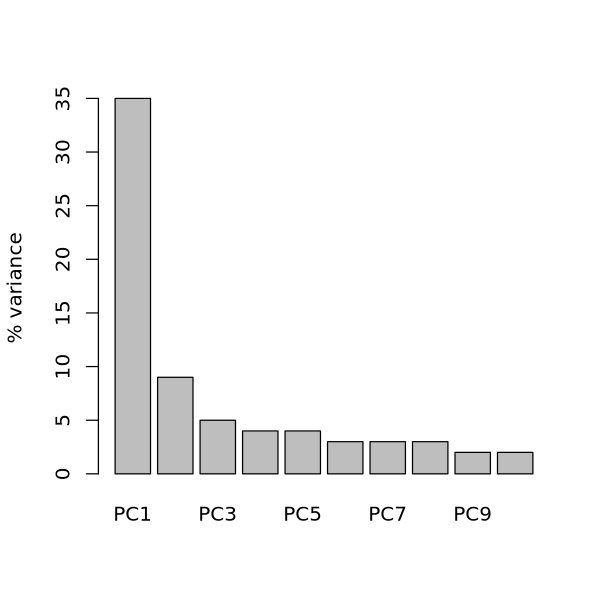

In [184]:
options(repr.plot.height = 5, repr.plot.width = 5)
barplot(percentVar[1:10], names.arg = paste0("PC", 1:10), ylab = "% variance")

doesn't look like adding other components does anything for my data

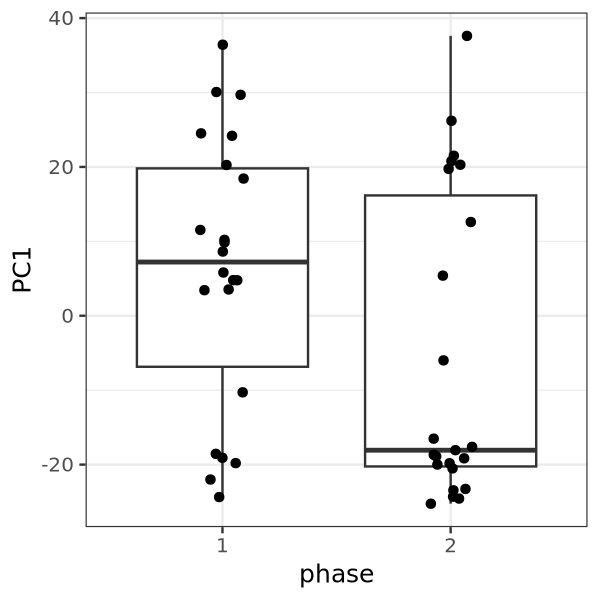

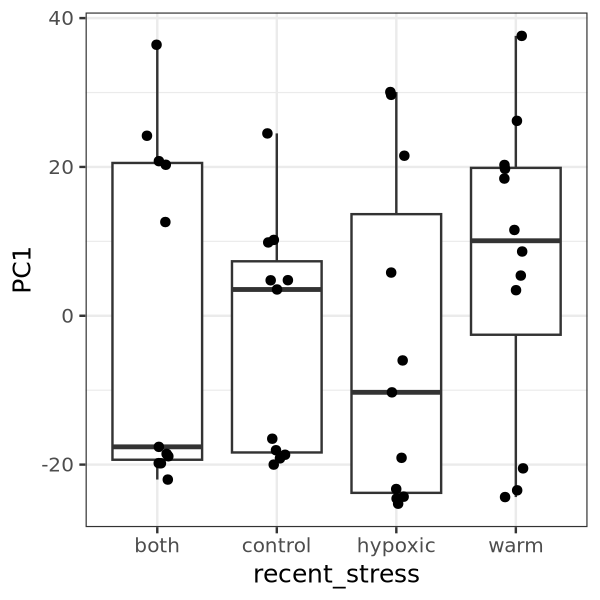

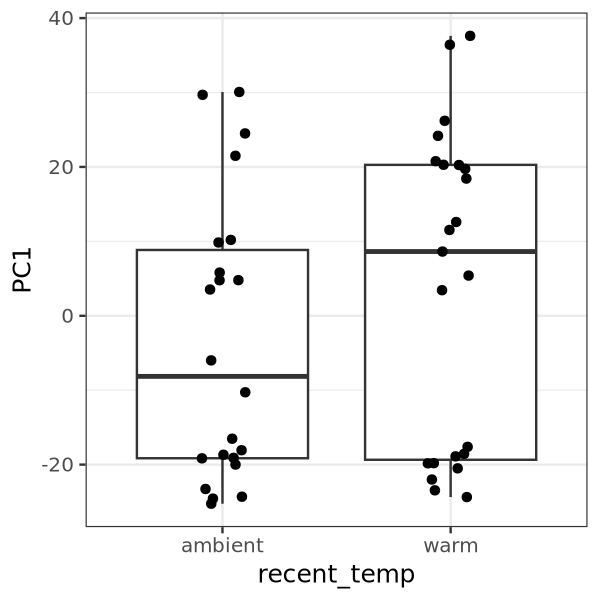

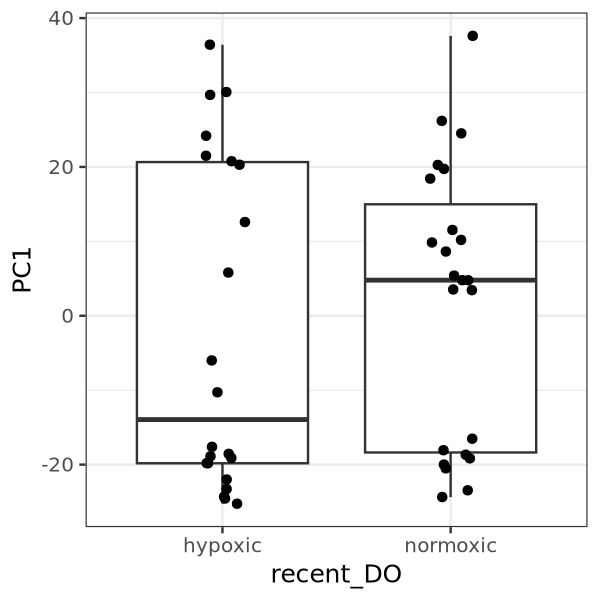

In [192]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(pcaData, aes(phase, PC1)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

ggplot(pcaData, aes(recent_stress, PC1)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

ggplot(pcaData, aes(recent_temp, PC1)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

ggplot(pcaData, aes(recent_DO, PC1)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

#ggplot(pcaData, aes(recent_temp, PC1, color = phase)) + geom_point() + geom_smooth(method = "lm")

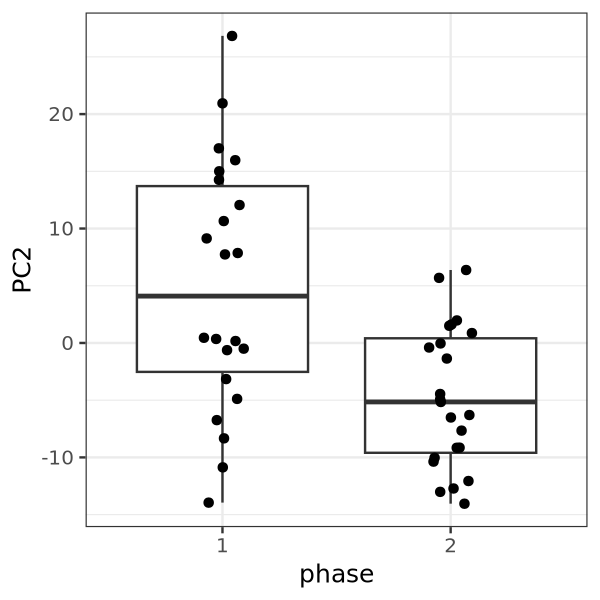

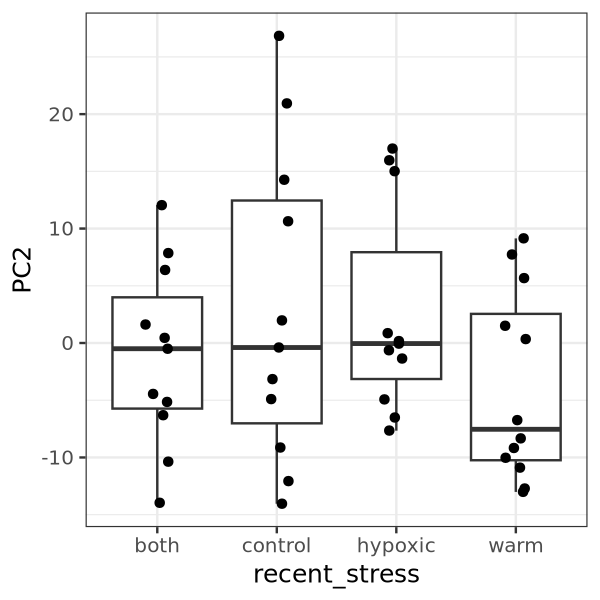

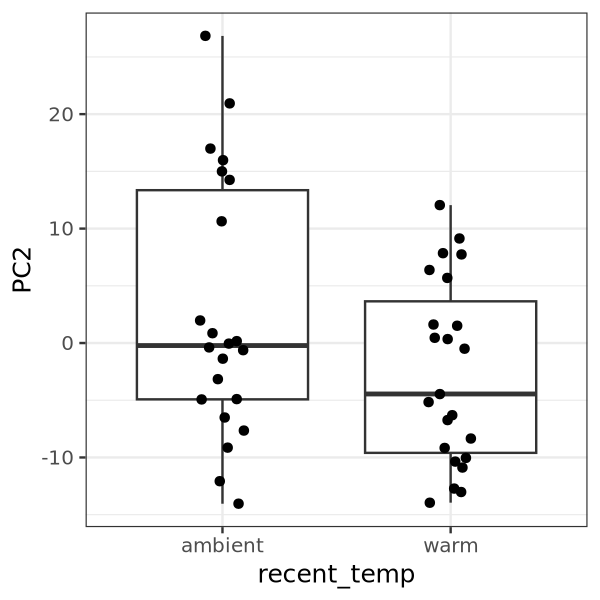

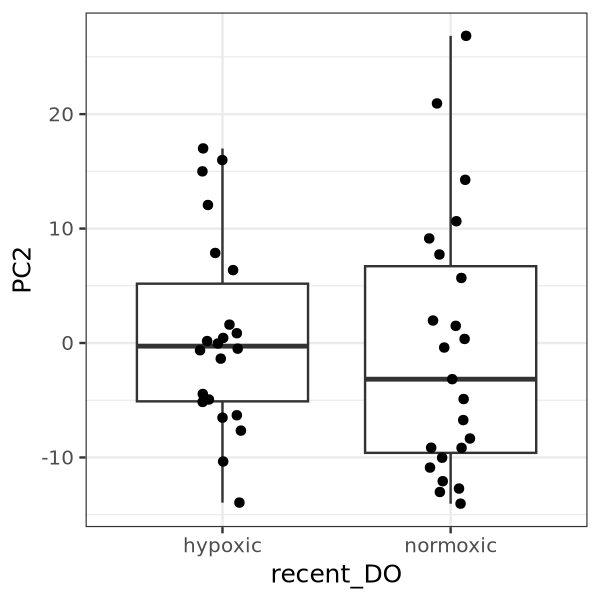

In [193]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(pcaData, aes(phase, PC2)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

ggplot(pcaData, aes(recent_stress, PC2)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

ggplot(pcaData, aes(recent_temp, PC2)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

ggplot(pcaData, aes(recent_DO, PC2)) + 
geom_boxplot() + 
geom_jitter(width = 0.1) + 
theme_bw(base_size = 15)

none of these variables seem to explain the variance observed in PC1

In [186]:
# look at R2 values for each PC and variable

vars <- c("phase", "recent_stress", "recent_temp", "recent_DO")
pcs  <- paste0("PC", 1:6)

r2 <- sapply(vars, function(v) {
  sapply(pcs, function(pc) {
    summary(lm(pcaData[[pc]] ~ pcaData[[v]]))$r.squared
  })
})
round(r2, 2)

,phase,recent_stress,recent_temp,recent_DO
PC1,0.09,0.05,0.03,0.01
PC2,0.24,0.08,0.07,0.00
PC3,0.14,0.05,0.00,0.04
PC4,0.00,0.04,0.03,0.00
PC5,0.11,0.03,0.01,0.02
PC6,0.17,0.04,0.01,0.02


a lot of the values are close to 0, so doesn't appear to be any strong relationships between PCs and variables

## 4. identify DEGs

In [195]:
resultsNames(dds_filtered)

[1] "Intercept"                                  
 [2] "complete_trtmt_both_control_vs_both_both"   
 [3] "complete_trtmt_both_hypoxic_vs_both_both"   
 [4] "complete_trtmt_both_NA_vs_both_both"        
 [5] "complete_trtmt_both_warm_vs_both_both"      
 [6] "complete_trtmt_control_both_vs_both_both"   
 [7] "complete_trtmt_control_control_vs_both_both"
 [8] "complete_trtmt_control_hypoxic_vs_both_both"
 [9] "complete_trtmt_control_NA_vs_both_both"     
[10] "complete_trtmt_control_warm_vs_both_both"   
[11] "complete_trtmt_hypoxic_both_vs_both_both"   
[12] "complete_trtmt_hypoxic_control_vs_both_both"
[13] "complete_trtmt_hypoxic_hypoxic_vs_both_both"
[14] "complete_trtmt_hypoxic_NA_vs_both_both"     
[15] "complete_trtmt_hypoxic_warm_vs_both_both"   
[16] "complete_trtmt_warm_both_vs_both_both"      
[17] "complete_trtmt_warm_control_vs_both_both"   
[18] "complete_trtmt_warm_hypoxic_vs_both_both"   
[19] "complete_trtmt_warm_NA_vs_both_both"        
[20] "complete_trtmt_warm_warm_vs_both_both"

#### C vs. CC
this tells us about differences in age when no stress is experienced

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041




out of 26062 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1552, 6%
LFC < 0 (down)     : 2304, 8.8%
outliers [1]       : 42, 0.16%
low counts [2]     : 1011, 3.9%
(mean count < 4)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.”


log2 fold change (MMSE): complete_trtmt control_control vs control_NA 
Wald test p-value: complete_trtmt control_control vs control_NA 
DataFrame with 6 rows and 5 columns
              baseMean log2FoldChange     lfcSE     pvalue      padj
             <numeric>      <numeric> <numeric>  <numeric> <numeric>
LOC144621260  2085.566     -0.0349167  0.195061 0.82834928 0.9325372
LOC144621269  2556.380     -0.8641853  1.335187 0.00638181 0.0575767
LOC111120925   142.064     -0.1439597  0.519130 0.26866576 0.5500665
LOC144621283   888.447      0.2418148  0.196562 0.13554762 0.3756686
LOC144621276 12535.469      0.3520186  0.183921 0.02365170 0.1301973
LOC111115920   180.466     -0.0161539  0.278325 0.92741119 0.9729897

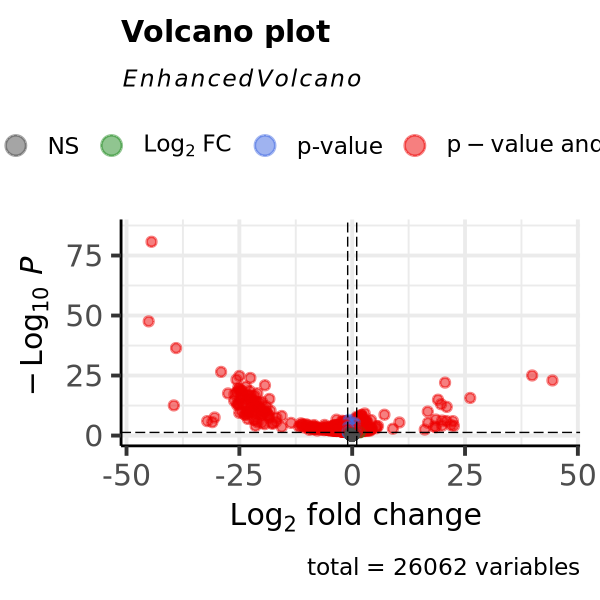

In [199]:
# phase 1 warm vs. control
res.contLFC <- lfcShrink(dds_filtered, 
                         contrast = c('complete_trtmt', 'control_control', 'control_NA'), # phase 1 C is the baseline
                         type = 'ashr')

summary(res.contLFC)

EnhancedVolcano(res.contLFC,
                lab=NA,
                x = 'log2FoldChange',
                y='padj',
                pCutoff=0.05)

head(res.contLFC)

wow ... DEGs in the 1000s ... I wonder if this has to do with differences in the tissue size used to extract the DNA/RNA? but the libraries are assumed to be normalized ... and were processed/sequenced together so I doubt that would be it

In [243]:
write.csv(as.data.frame(res.contLFC), '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cc_c.csv')

#### W vs. CW
response warm stress at different ages

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041




out of 26062 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 506, 1.9%
LFC < 0 (down)     : 449, 1.7%
outliers [1]       : 42, 0.16%
low counts [2]     : 1011, 3.9%
(mean count < 4)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



log2 fold change (MMSE): complete_trtmt control_warm vs warm_NA 
Wald test p-value: complete_trtmt control_warm vs warm_NA 
DataFrame with 6 rows and 5 columns
              baseMean log2FoldChange     lfcSE    pvalue      padj
             <numeric>      <numeric> <numeric> <numeric> <numeric>
LOC144621260  2085.566     0.04987341  0.148763  0.609851  0.895583
LOC144621269  2556.380     0.01446290  0.255236  0.737738  0.937409
LOC111120925   142.064    -0.00330971  0.257878  0.936232  0.987485
LOC144621283   888.447     0.07541640  0.148583  0.442332  0.823624
LOC144621276 12535.469     0.11084748  0.141674  0.261874  0.699197
LOC111115920   180.466     0.05982414  0.188031  0.468633  0.835250

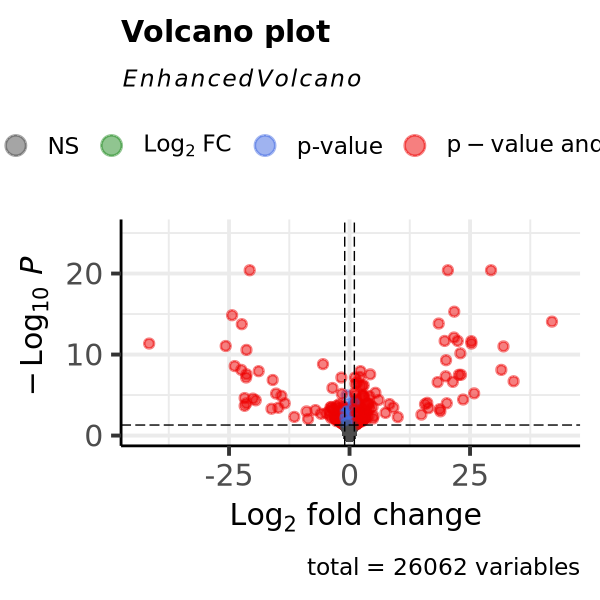

In [200]:
# W vs. CW
res.warmAgeLFC <- lfcShrink(dds_filtered, 
                         contrast = c('complete_trtmt', 'control_warm', 'warm_NA'), # phase 1 W is the baseline
                         type = 'ashr')

summary(res.warmAgeLFC)

EnhancedVolcano(res.warmAgeLFC,
                lab=NA,
                x = 'log2FoldChange',
                y='padj',
                pCutoff=0.05)

head(res.warmAgeLFC)

In [242]:
write.csv(as.data.frame(res.warmAgeLFC), '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cw_w.csv')

#### H vs. CH
response to hypoxic stress at different ages

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041




out of 26062 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1156, 4.4%
LFC < 0 (down)     : 1238, 4.8%
outliers [1]       : 42, 0.16%
low counts [2]     : 1516, 5.8%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



log2 fold change (MMSE): complete_trtmt control_hypoxic vs hypoxic_NA 
Wald test p-value: complete_trtmt control_hypoxic vs hypoxic_NA 
DataFrame with 6 rows and 5 columns
              baseMean log2FoldChange     lfcSE    pvalue      padj
             <numeric>      <numeric> <numeric> <numeric> <numeric>
LOC144621260  2085.566    -0.21663617  0.187977 0.1196487  0.379078
LOC144621269  2556.380    -0.13369142  0.479566 0.2128874  0.505459
LOC111120925   142.064    -0.21514739  0.628434 0.0883887  0.324786
LOC144621283   888.447     0.30092532  0.195397 0.0354410  0.201589
LOC144621276 12535.469     0.07598009  0.165356 0.5601682  0.799046
LOC111115920   180.466    -0.00514329  0.243173 0.9697180  0.990237

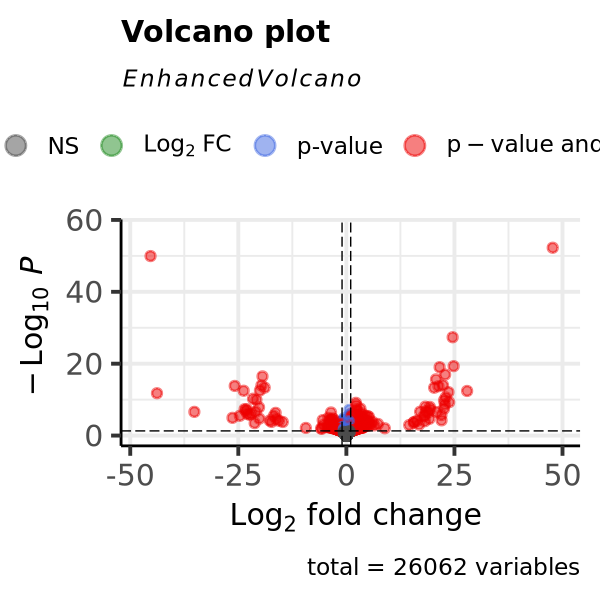

In [201]:
# H vs. CH
res.hypoxicAgeLFC <- lfcShrink(dds_filtered, 
                         contrast = c('complete_trtmt', 'control_hypoxic', 'hypoxic_NA'), # phase 1 H is the baseline
                         type = 'ashr')

summary(res.hypoxicAgeLFC)

EnhancedVolcano(res.hypoxicAgeLFC,
                lab=NA,
                x = 'log2FoldChange',
                y='padj',
                pCutoff=0.05)

head(res.hypoxicAgeLFC)

In [241]:
write.csv(as.data.frame(res.hypoxicAgeLFC), '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/ch_h.csv')

#### B vs. CB
response to both warm and hypoxic stress at different ages

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041




out of 26062 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1113, 4.3%
LFC < 0 (down)     : 1092, 4.2%
outliers [1]       : 42, 0.16%
low counts [2]     : 1516, 5.8%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



log2 fold change (MMSE): complete_trtmt control_both vs both_NA 
Wald test p-value: complete_trtmt control_both vs both_NA 
DataFrame with 6 rows and 5 columns
              baseMean log2FoldChange     lfcSE     pvalue      padj
             <numeric>      <numeric> <numeric>  <numeric> <numeric>
LOC144621260  2085.566     -0.0456306  0.183346 0.74829760 0.9145279
LOC144621269  2556.380     -0.0650017  0.378990 0.44065402 0.7485986
LOC111120925   142.064      0.9113969  1.557471 0.00248705 0.0474631
LOC144621283   888.447      0.1531968  0.183042 0.28196217 0.6216665
LOC144621276 12535.469      0.4142475  0.180750 0.00362716 0.0594395
LOC111115920   180.466     -0.2612904  0.275929 0.08001999 0.3300560

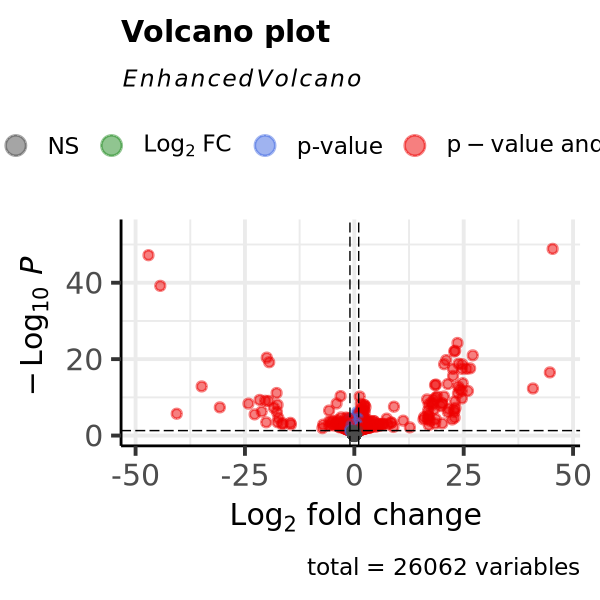

In [202]:
# B vs. CB
res.bothAgeLFC <- lfcShrink(dds_filtered, 
                         contrast = c('complete_trtmt', 'control_both', 'both_NA'), # phase 1 B is the baseline
                         type = 'ashr')

summary(res.bothAgeLFC)

EnhancedVolcano(res.bothAgeLFC,
                lab=NA,
                x = 'log2FoldChange',
                y='padj',
                pCutoff=0.05)

head(res.bothAgeLFC)

In [240]:
write.csv(as.data.frame(res.bothAgeLFC), '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/deseq_res/cb_b.csv')

## 5. vst heatmaps

In [210]:
vst.mat <- assay(vsd)
head(vst.mat)

,B1_B1_O01,B1_Nu_O03,B1_W5_O50,B2_B5_O51,B2_C4_O40,B2_Nu_O12,B3_B4_O41,B3_C3_O30,B3_C6_O66,B3_H4_O41,⋯,W5_C4_G45,W5_H4_G46,W5_W2_G22,W6_B3_G35,W6_B4_G48,W6_H6_G71,W6_Nu_G41,W6_Nu_G45,W6_W3_G36,W6_W4_G48
LOC144621260,11.620179,11.198703,11.408773,11.390662,11.249354,11.833038,10.958404,10.942136,11.350035,11.029669,⋯,11.075024,11.537052,11.397286,11.217570,11.353508,11.198966,11.382870,11.537133,11.816524,11.650533
LOC144621269,8.737758,9.752041,11.133191,11.557985,10.481672,13.989121,11.602981,10.638752,12.865725,11.035823,⋯,8.341078,10.159815,8.666374,9.012078,13.525745,8.473097,8.205924,12.196581,9.820636,13.498445
LOC111120925,8.818346,8.241650,8.525800,9.873731,8.374239,8.423747,8.469501,8.352582,8.096564,8.187923,⋯,8.269565,9.893771,8.870204,8.584406,8.311706,8.190947,8.096564,8.389839,8.405851,8.373651
LOC144621283,10.028354,10.183004,10.460543,10.482047,10.305941,10.386954,10.404502,10.691809,10.654265,9.890968,⋯,10.347679,10.485569,10.456853,10.375445,10.098367,10.972317,10.324274,10.378375,10.113462,10.141210
LOC144621276,13.528414,13.298912,13.572128,13.742292,13.576708,13.536560,13.860035,13.983874,13.793368,13.301977,⋯,13.931588,13.623051,13.172438,13.362633,14.013263,13.453280,13.645595,13.328236,13.497403,13.442051
LOC111115920,9.202520,9.441435,9.272325,9.169626,9.011131,9.309108,8.932148,8.880005,8.786389,9.758398,⋯,9.458789,9.114476,9.783374,9.789237,9.274121,9.438293,9.118541,8.951868,8.955310,9.065907


In [220]:
meta2$Sample <- rownames(meta2)
head(meta2)

,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt,phase,recent_stress,recent_temp,recent_DO,Sample
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic,B1_Nu_O03
B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic,B2_Nu_O12
B4_Nu_O32,both,warm,hypoxic,4,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic,B4_Nu_O32
B5_Nu_O36,both,warm,hypoxic,5,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic,B5_Nu_O36
B6_Nu_O47,both,warm,hypoxic,6,NA,NA,NA,NA,both_NA,1,both,warm,hypoxic,B6_Nu_O47
C_W5_W52,control,ambient,normoxic,NA,warm,warm,normoxic,5,control_warm,2,warm,warm,normoxic,C_W5_W52


In [231]:
dim(meta2)
dim(vst.mat)

[1] 45 14

[1] 26062   115

In [232]:
head(vst.mat)

,B1_B1_O01,B1_Nu_O03,B1_W5_O50,B2_B5_O51,B2_C4_O40,B2_Nu_O12,B3_B4_O41,B3_C3_O30,B3_C6_O66,B3_H4_O41,⋯,W5_C4_G45,W5_H4_G46,W5_W2_G22,W6_B3_G35,W6_B4_G48,W6_H6_G71,W6_Nu_G41,W6_Nu_G45,W6_W3_G36,W6_W4_G48
LOC144621260,11.620179,11.198703,11.408773,11.390662,11.249354,11.833038,10.958404,10.942136,11.350035,11.029669,⋯,11.075024,11.537052,11.397286,11.217570,11.353508,11.198966,11.382870,11.537133,11.816524,11.650533
LOC144621269,8.737758,9.752041,11.133191,11.557985,10.481672,13.989121,11.602981,10.638752,12.865725,11.035823,⋯,8.341078,10.159815,8.666374,9.012078,13.525745,8.473097,8.205924,12.196581,9.820636,13.498445
LOC111120925,8.818346,8.241650,8.525800,9.873731,8.374239,8.423747,8.469501,8.352582,8.096564,8.187923,⋯,8.269565,9.893771,8.870204,8.584406,8.311706,8.190947,8.096564,8.389839,8.405851,8.373651
LOC144621283,10.028354,10.183004,10.460543,10.482047,10.305941,10.386954,10.404502,10.691809,10.654265,9.890968,⋯,10.347679,10.485569,10.456853,10.375445,10.098367,10.972317,10.324274,10.378375,10.113462,10.141210
LOC144621276,13.528414,13.298912,13.572128,13.742292,13.576708,13.536560,13.860035,13.983874,13.793368,13.301977,⋯,13.931588,13.623051,13.172438,13.362633,14.013263,13.453280,13.645595,13.328236,13.497403,13.442051
LOC111115920,9.202520,9.441435,9.272325,9.169626,9.011131,9.309108,8.932148,8.880005,8.786389,9.758398,⋯,9.458789,9.114476,9.783374,9.789237,9.274121,9.438293,9.118541,8.951868,8.955310,9.065907


In [237]:
annotation <- meta2 %>%
  select(Sample, phase, recent_stress, recent_temp, recent_DO)
  #column_to_rownames("Sample")

vst.subset <- vst.mat[,colnames(vst.mat) %in% rownames(meta2)]

annotation_colors <- list(
  recent_stress = c(
    control = "burlywood3",
    warm = "palevioletred",
      hypoxic = 'steelblue3',
      both = 'plum3'
  ),
  phase = c(
    '2' = 'blue', '1' = 'lightblue'
  )
)

head(annotation)
head(annotation_colors)

,Sample,phase,recent_stress,recent_temp,recent_DO
,<chr>,<chr>,<chr>,<chr>,<chr>
B1_Nu_O03,B1_Nu_O03,1,both,warm,hypoxic
B2_Nu_O12,B2_Nu_O12,1,both,warm,hypoxic
B4_Nu_O32,B4_Nu_O32,1,both,warm,hypoxic
B5_Nu_O36,B5_Nu_O36,1,both,warm,hypoxic
B6_Nu_O47,B6_Nu_O47,1,both,warm,hypoxic
C_W5_W52,C_W5_W52,2,warm,warm,normoxic


$recent_stress
        control            warm         hypoxic            both 
   "burlywood3" "palevioletred"    "steelblue3"         "plum3" 

$phase
          2           1 
     "blue" "lightblue"

`use_raster` is automatically set to TRUE for a matrix with more than
2000 rows. You can control `use_raster` argument by explicitly setting
TRUE/FALSE to it.

Set `ht_opt$message = FALSE` to turn off this message.

'magick' package is suggested to install to give better rasterization.

Set `ht_opt$message = FALSE` to turn off this message.



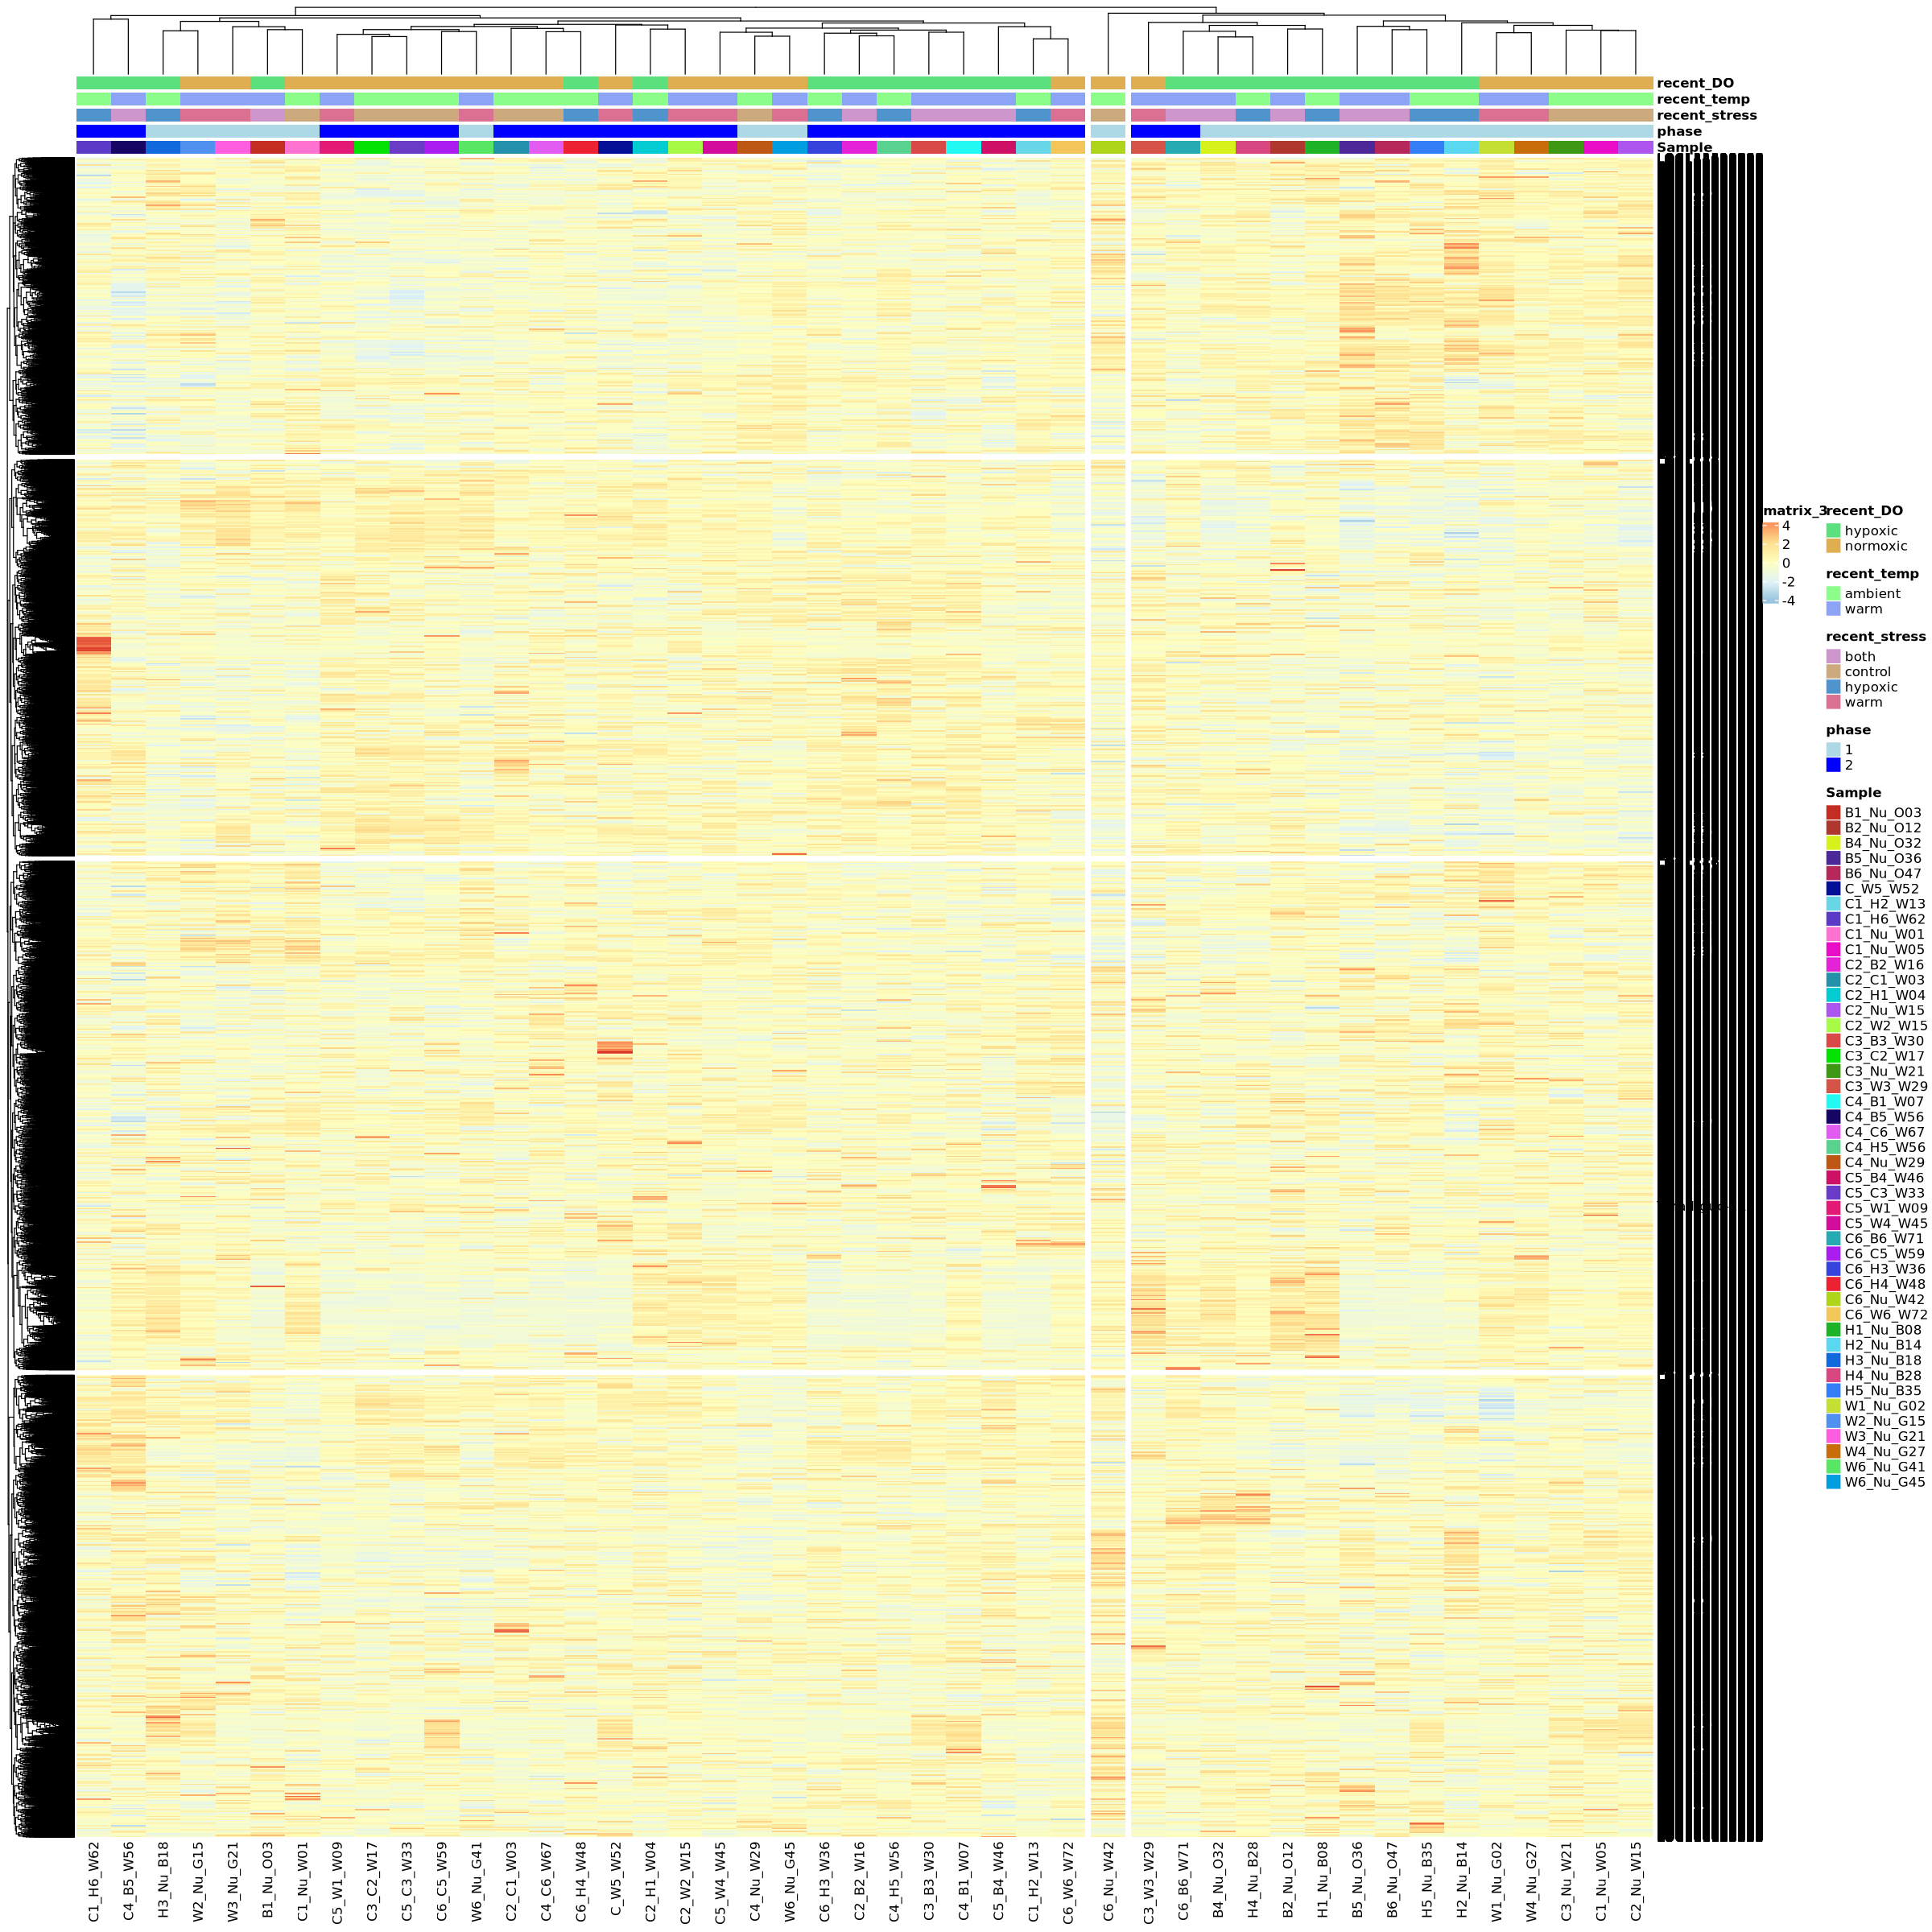

In [239]:
options(repr.plot.height = 20, repr.plot.width = 20)

pheatmap(vst.subset,
         #cluster_cols = FALSE,
        annotation_col = annotation,
         annotation_colors = annotation_colors,
         cutree_rows = 4, 
         cutree_cols = 3,
        scale = 'row' # standardizes each gene separately across samples
        ) 